# Лабораторная работа №1. Методы классификации

## Задание 1. Наивный байесовский классификатор: влияние объёма обучающей выборки
### 1a. Крестики-нолики (tic_tac_toe.txt)
958 позиций игры, 9 признаков - клетки поля (x, o или b - пусто), класс - выиграли ли крестики (positive / negative).

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ttt=pd.read_csv('tic_tac_toe.txt', header=None)
print(ttt.shape)
ttt.head()

(958, 10)


,0,1,2,3,4,5,6,7,8,9
0,x,x,x,x,o,o,x,o,o,positive
1,x,x,x,x,o,o,o,x,o,positive
2,x,x,x,x,o,o,o,o,x,positive
3,x,x,x,x,o,o,o,b,b,positive
4,x,x,x,x,o,o,b,o,b,positive


In [90]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score

X = OrdinalEncoder().fit_transform(ttt.iloc[:, :9])  # признаки: x/o/b -> числа
y = ttt[9]                                           # класс: positive/negative

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

model = CategoricalNB()
model.fit(X_train, y_train)
print('train:', accuracy_score(y_train, model.predict(X_train)))
print('test :', accuracy_score(y_test, model.predict(X_test)))

train: 0.7134328358208956
test : 0.6875


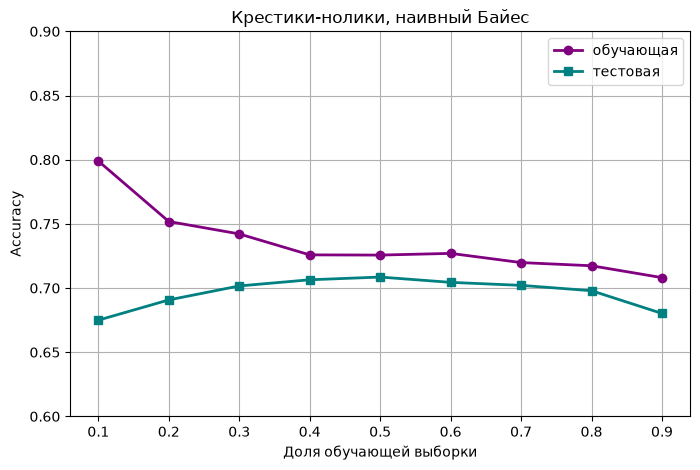

In [91]:
ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
train_acc, test_acc = [], []

for r in ratios:
    tr, te = [], []
    for seed in range(10):   # 10 разных случайных разбиений
        X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=r, random_state=seed)
        model = CategoricalNB(min_categories=3).fit(X_train, y_train)
        tr.append(accuracy_score(y_train, model.predict(X_train)))
        te.append(accuracy_score(y_test, model.predict(X_test)))
    train_acc.append(np.mean(tr))
    test_acc.append(np.mean(te))

plt.figure(figsize=(8, 5))
plt.plot(ratios, train_acc, marker='o', color='purple', linewidth=2, label='обучающая')
plt.plot(ratios, test_acc, marker='s', color='teal', linewidth=2, label='тестовая')
plt.xlabel('Доля обучающей выборки')
plt.ylabel('Accuracy')
plt.title('Крестики-нолики, наивный Байес')
plt.legend()
plt.grid(True)
plt.ylim(0.6, 0.9)
plt.show()

In [92]:
pd.DataFrame({'Доля train': ratios,
              'Accuracy train': train_acc,
              'Accuracy test': test_acc}).round(3)

,Доля train,Accuracy train,Accuracy test
0,0.1,0.799,0.675
1,0.2,0.752,0.691
2,0.3,0.742,0.702
3,0.4,0.726,0.706
4,0.5,0.726,0.709
5,0.6,0.727,0.704
6,0.7,0.720,0.702
7,0.8,0.717,0.698
8,0.9,0.708,0.680


### 1b. Спам (spam.csv)
4601 письмо, 57 числовых признаков (частоты слов и символов, длины последовательностей заглавных букв), класс - spam / nonspam. Признаки непрерывные, поэтому используется гауссов наивный Байес (GaussianNB).

In [93]:
from sklearn.naive_bayes import GaussianNB

spam = pd.read_csv('spam.csv')
print(spam.shape)
X_s = spam.drop(columns=[spam.columns[0], 'type'])  # признаки
y_s = spam['type']                                   # класс: spam / nonspam
print(y_s.value_counts())

(4601, 59)
type
nonspam    2788
spam       1813
Name: count, dtype: int64


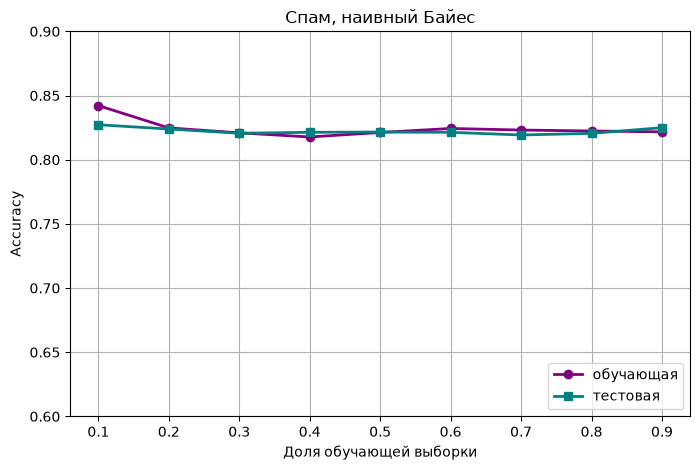

In [94]:
ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
train_acc_s, test_acc_s = [], []

for r in ratios:
    tr, te = [], []
    for seed in range(10):   # 10 разных случайных разбиений
        X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, train_size=r, random_state=seed)
        model = GaussianNB().fit(X_train, y_train)
        tr.append(accuracy_score(y_train, model.predict(X_train)))
        te.append(accuracy_score(y_test, model.predict(X_test)))
    train_acc_s.append(np.mean(tr))
    test_acc_s.append(np.mean(te))

plt.figure(figsize=(8, 5))
plt.plot(ratios, train_acc_s, marker='o', color='purple', linewidth=2, label='обучающая')
plt.plot(ratios, test_acc_s, marker='s', color='teal', linewidth=2, label='тестовая')
plt.xlabel('Доля обучающей выборки')
plt.ylabel('Accuracy')
plt.title('Спам, наивный Байес')
plt.legend(loc='lower right')
plt.grid(True)
plt.ylim(0.6, 0.9)
plt.show()

In [95]:
pd.DataFrame({'Доля train': ratios,
              'Accuracy train': train_acc_s,
              'Accuracy test': test_acc_s}).round(3)

,Доля train,Accuracy train,Accuracy test
0,0.1,0.842,0.827
1,0.2,0.825,0.824
2,0.3,0.821,0.821
3,0.4,0.818,0.821
4,0.5,0.821,0.822
5,0.6,0.824,0.821
6,0.7,0.823,0.819
7,0.8,0.822,0.821
8,0.9,0.822,0.825


### Выводы по заданию 1
Соотношение обучающей и тестовой выборок влияет на точность наивного байесовского классификатора по-разному для двух наборов. На крестиках-ноликах при малой обучающей выборке модель переобучается: при доле 0.1 точность на обучающей выборке 0.80, а на тестовой только 0.675. С ростом обучающей выборки линии сближаются и при доле 0.4–0.6 сходятся около 0.71. Выше этого уровня точность не поднимается: наивный Байес считает клетки независимыми при известном классе, а исход партии определяется сочетанием трёх клеток в ряд, поэтому результат ненамного лучше доли класса positive (0.65).

На наборе spam точность около 0.82 почти не зависит от доли обучающей выборки: у GaussianNB мало параметров (среднее и дисперсия каждого признака в классе), поэтому ему хватает даже 10 % данных, и он почти не переобучается. При доле 0.9 тестовая выборка становится слишком маленькой, и оценка точности на ней ненадёжна. Разумно отдавать на обучение 60–80 % данных, а остальное оставлять для теста.

## Задание 2. Генерация двумерной выборки и наивный Байес (вариант 6)
Класс −1: 60 точек, X1 имеет нормальное распределение со средним 19 и среднеквадратическим отклонением 3, X2 - со средним 12 и отклонением 3.
Класс 1: 40 точек, X1 - среднее 13, отклонение 5; X2 - среднее 6, отклонение 5.

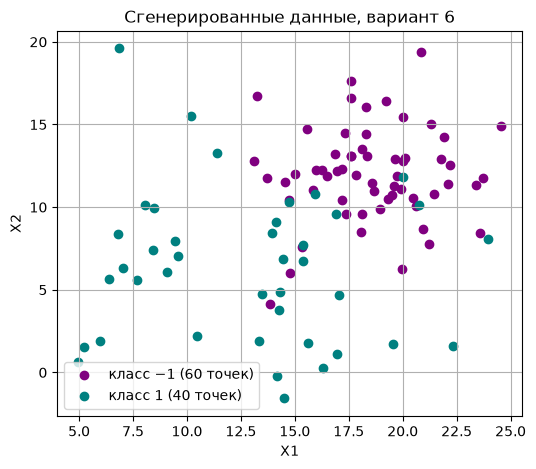

In [96]:
np.random.seed(42)
n_neg, n_pos = 60, 40

# класс −1: мат. ожидание X1 = 19, X2 = 12, СКО = 3
X_neg = np.column_stack([np.random.normal(19, 3, n_neg), np.random.normal(12, 3, n_neg)])
# класс 1: мат. ожидание X1 = 13, X2 = 6, СКО = 5
X_pos = np.column_stack([np.random.normal(13, 5, n_pos), np.random.normal(6, 5, n_pos)])

X2 = np.vstack([X_neg, X_pos])
y2 = np.array([-1] * n_neg + [1] * n_pos)

plt.figure(figsize=(6, 5))
plt.scatter(X_neg[:, 0], X_neg[:, 1], color='purple', label='класс −1 (60 точек)')
plt.scatter(X_pos[:, 0], X_pos[:, 1], color='teal', label='класс 1 (40 точек)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Сгенерированные данные, вариант 6')
plt.legend()
plt.grid(True)
plt.show()

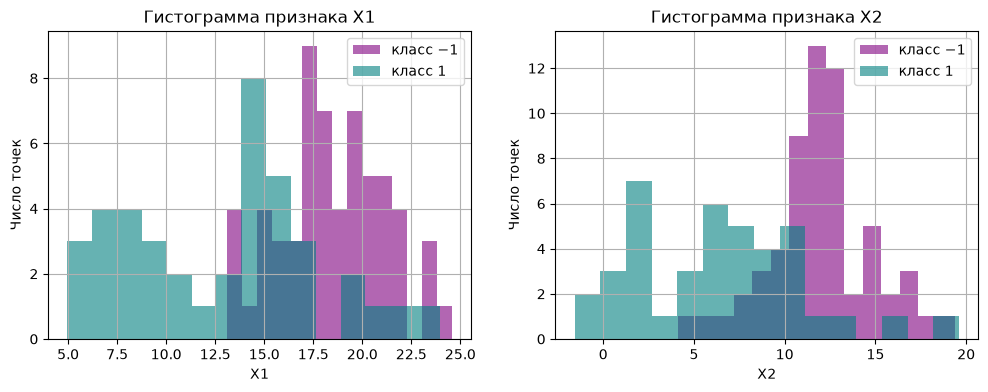

In [97]:
# Распределение каждого признака по классам
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j, name in enumerate(['X1', 'X2']):
    ax[j].hist(X_neg[:, j], bins=15, alpha=0.6, color='purple', label='класс −1')
    ax[j].hist(X_pos[:, j], bins=15, alpha=0.6, color='teal', label='класс 1')
    ax[j].set_xlabel(name)
    ax[j].set_ylabel('Число точек')
    ax[j].set_title(f'Гистограмма признака {name}')
    ax[j].legend()
    ax[j].grid(True)
plt.show()

accuracy train: 0.9285714285714286
accuracy test : 0.8666666666666667
[[16  2]
 [ 2 10]]


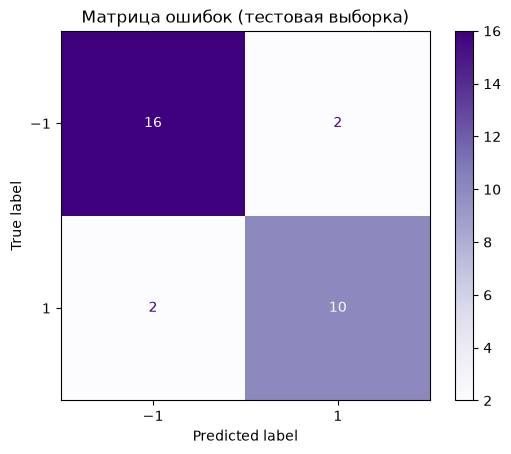

In [98]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.3, random_state=42, stratify=y2)

nb = GaussianNB().fit(X2_train, y2_train)
y2_pred = nb.predict(X2_test)

print('accuracy train:', accuracy_score(y2_train, nb.predict(X2_train)))
print('accuracy test :', accuracy_score(y2_test, y2_pred))

cm = confusion_matrix(y2_test, y2_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=['−1', '1']).plot(cmap='Purples')
plt.title('Матрица ошибок (тестовая выборка)')
plt.show()

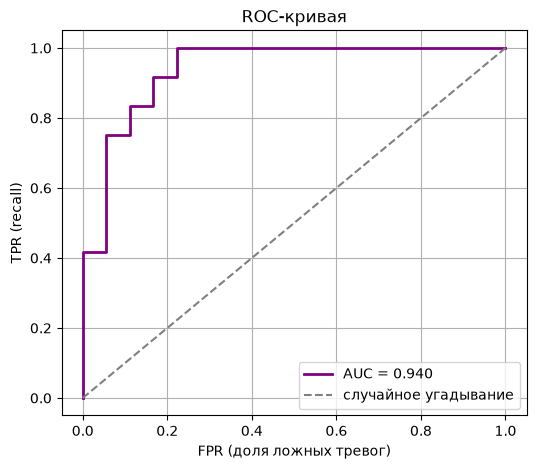

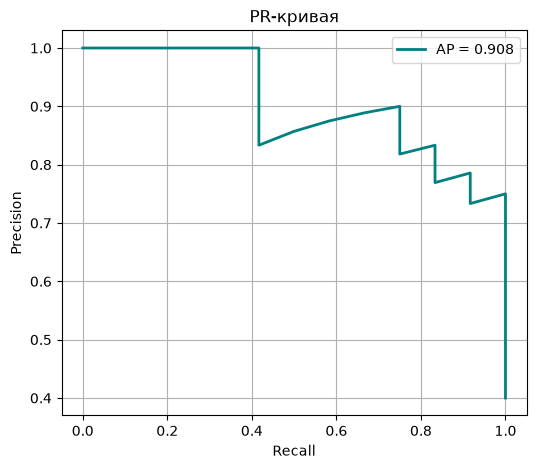

In [99]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

proba = nb.predict_proba(X2_test)[:, 1]   # вероятность класса 1 для каждой точки

fpr, tpr, _ = roc_curve(y2_test, proba)
prec, rec, _ = precision_recall_curve(y2_test, proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='purple', linewidth=2, label=f'AUC = {roc_auc_score(y2_test, proba):.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray', label='случайное угадывание')
plt.xlabel('FPR (доля ложных тревог)')
plt.ylabel('TPR (recall)')
plt.title('ROC-кривая')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(6, 5))
plt.plot(rec, prec, color='teal', linewidth=2, label=f'AP = {average_precision_score(y2_test, proba):.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривая')
plt.legend()
plt.grid(True)
plt.show()

### Выводы по заданию 2
Сгенерированная по варианту 6 выборка состоит из двух частично перекрывающихся облаков: у класса 1 разброс больше (среднеквадратическое отклонение 5 против 3), и его облако заходит на облако класса -1. В зоне пересечения безошибочная классификация невозможна никаким методом.

Наивный байесовский классификатор даёт accuracy 0.929 на обучающей и 0.867 на тестовой выборке, значит, сильного переобучения нет. По матрице ошибок 16 и 10 точек классифицированы верно, сделано 4 ошибки (2 ложных срабатывания и 2 пропуска), все в зоне пересечения облаков; precision и recall для класса 1 равны 0.83. ROC AUC = 0.940 и AP = 0.908 близки к 1. Итог: байесовский классификатор для сгенерированных данных является хорошим - он ошибается только там, где классы перекрываются.

## Задание 3. Метод k ближайших соседей (glass.csv)
214 образцов стекла, 9 признаков (показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe), 6 типов стекла. Столбец Id удаляется. Признаки стандартизуются: kNN считает расстояния, и без этого признак с большими числами (например, Si ≈ 72) задавил бы остальные.

In [100]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

glass = pd.read_csv('glass.csv')
print(glass.shape)
print(glass['Type'].value_counts().sort_index())

X3 = glass.drop(columns=['Id', 'Type'])   # Id — просто номер, убираем по заданию
y3 = glass['Type']

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.3, random_state=42, stratify=y3)

scaler = StandardScaler().fit(X3_train)   # считаем среднее и СКО на обучающей
X3_train_s = scaler.transform(X3_train)
X3_test_s = scaler.transform(X3_test)

(214, 11)
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


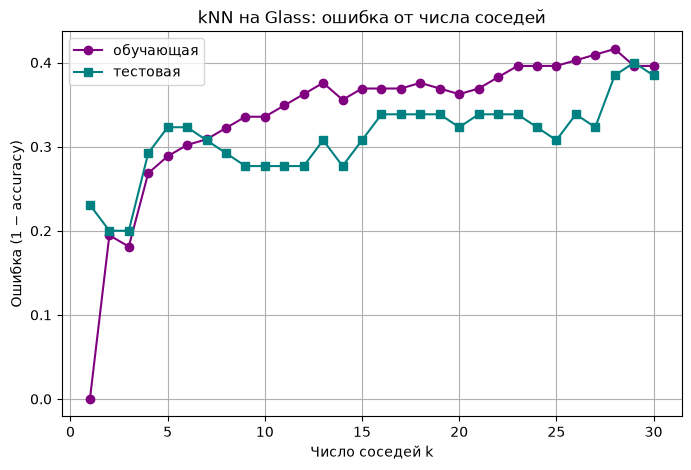

In [101]:
ks = range(1, 31)
err_train, err_test = [], []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X3_train_s, y3_train)
    err_train.append(1 - knn.score(X3_train_s, y3_train))
    err_test.append(1 - knn.score(X3_test_s, y3_test))

plt.figure(figsize=(8, 5))
plt.plot(ks, err_train, marker='o', color='purple', label='обучающая')
plt.plot(ks, err_test, marker='s', color='teal', label='тестовая')
plt.xlabel('Число соседей k')
plt.ylabel('Ошибка (1 − accuracy)')
plt.title('kNN на Glass: ошибка от числа соседей')
plt.legend()
plt.grid(True)
plt.show()

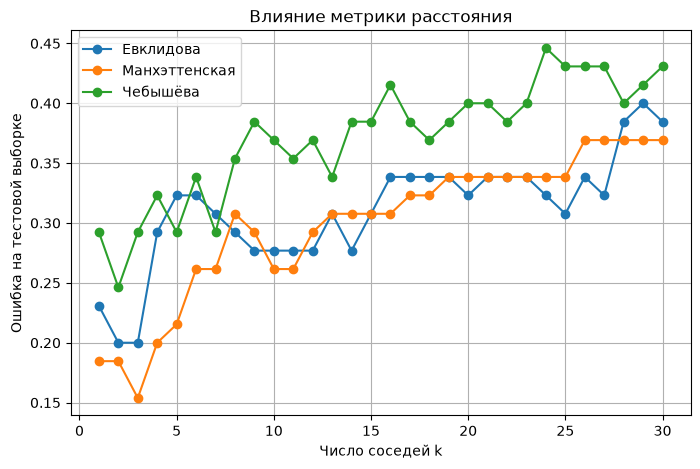

In [102]:
metrics = {'Евклидова': 'euclidean', 'Манхэттенская': 'manhattan', 'Чебышёва': 'chebyshev'}

plt.figure(figsize=(8, 5))
for name, metric in metrics.items():
    errs = []
    for k in ks:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(X3_train_s, y3_train)
        errs.append(1 - knn.score(X3_test_s, y3_test))
    plt.plot(ks, errs, marker='o', label=name)

plt.xlabel('Число соседей k')
plt.ylabel('Ошибка на тестовой выборке')
plt.title('Влияние метрики расстояния')
plt.legend()
plt.grid(True)
plt.show()

In [103]:
# Таблица: ошибка на тестовой выборке для разных k и метрик
err_metric = {}
for name, metric in metrics.items():
    err_metric[name] = [1 - KNeighborsClassifier(n_neighbors=k, metric=metric)
                        .fit(X3_train_s, y3_train).score(X3_test_s, y3_test) for k in ks]

err_tab = pd.DataFrame(err_metric, index=ks).round(3)
err_tab.index.name = 'k'
print('Минимальная ошибка:', err_tab.min().to_dict())
print('при k =', err_tab.idxmin().to_dict())
err_tab.loc[[1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30]]

Минимальная ошибка: {'Евклидова': 0.2, 'Манхэттенская': 0.154, 'Чебышёва': 0.246}
при k = {'Евклидова': 2, 'Манхэттенская': 3, 'Чебышёва': 2}


,Евклидова,Манхэттенская,Чебышёва
k,,,
1,0.231,0.185,0.292
2,0.200,0.185,0.246
3,0.200,0.154,0.292
4,0.292,0.200,0.323
5,0.323,0.215,0.292
7,0.308,0.262,0.292
10,0.277,0.262,0.369
15,0.308,0.308,0.385
20,0.323,0.338,0.400


In [104]:
# Лучшее k для каждой метрики (минимальная ошибка на тесте, при равенстве — меньшее k)
best_rows = []
for name, metric in metrics.items():
    errs = []
    for k in ks:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(X3_train_s, y3_train)
        errs.append((1 - knn.score(X3_test_s, y3_test), k, 1 - knn.score(X3_train_s, y3_train)))
    e_te, k_best, e_tr = min(errs)
    best_rows.append({'метрика': name, 'лучшее k': k_best, 'ошибка train': round(e_tr, 3),
                      'ошибка test': round(e_te, 3), 'accuracy test': round(1 - e_te, 3)})
pd.DataFrame(best_rows)

,метрика,лучшее k,ошибка train,ошибка test,accuracy test
0,Евклидова,2,0.195,0.200,0.800
1,Манхэттенская,3,0.168,0.154,0.846
2,Чебышёва,2,0.208,0.246,0.754


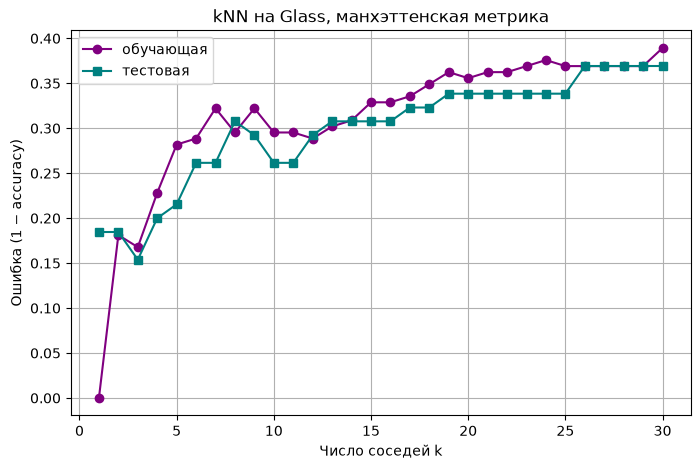

In [105]:
# Лучшая метрика (манхэттенская): ошибка на обучающей и тестовой выборках
err_tr_m, err_te_m = [], []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k, metric='manhattan').fit(X3_train_s, y3_train)
    err_tr_m.append(1 - knn.score(X3_train_s, y3_train))
    err_te_m.append(1 - knn.score(X3_test_s, y3_test))

plt.figure(figsize=(8, 5))
plt.plot(ks, err_tr_m, marker='o', color='purple', label='обучающая')
plt.plot(ks, err_te_m, marker='s', color='teal', label='тестовая')
plt.xlabel('Число соседей k')
plt.ylabel('Ошибка (1 − accuracy)')
plt.title('kNN на Glass, манхэттенская метрика')
plt.legend()
plt.grid(True)
plt.show()

In [106]:
sample = pd.DataFrame([[1.516, 11.7, 1.01, 1.19, 72.59, 0.43, 11.44, 0.02, 0.1]],
                      columns=X3.columns)
knn = KNeighborsClassifier(n_neighbors=3).fit(X3_train_s, y3_train)
print('Тип стекла:', knn.predict(scaler.transform(sample))[0])

Тип стекла: 5


### Выводы по заданию 3
От числа соседей k ошибка зависит сильно: при k = 1 модель запоминает обучающую выборку и переобучается, при большом k решение сглаживается в пользу частых классов, и малые классы перестают распознаваться. Наименьшая ошибка на тестовой выборке получена при k = 2–3.

Выбор метрики расстояния тоже важен: на этой выборке лучше всего работает манхэттенская метрика при k = 3 (accuracy 0.846 на тесте), хуже всех - метрика Чебышёва (0.754). После стандартизации признаков kNN работает намного лучше константного классификатора (0.354). Заданный в условии образец отнесён к типу 5 (стеклянная тара).

## Задание 4. Метод опорных векторов (SVC)
Функция `load_svm` читает файл и кодирует цвет: green = 1, red = 0. Функция `plot_svm` рисует области классов, точки и опорные векторы (обведены кружками).

In [107]:
from sklearn.svm import SVC

def load_svm(path):
    df = pd.read_csv(path, sep=r'\s+')
    color = 'Color' if 'Color' in df.columns else 'Colors'
    X = df[['X1', 'X2']].values
    y = (df[color] == 'green').astype(int).values   # green = 1, red = 0
    return X, y

def plot_svm(model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.25, cmap='RdYlGn')
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c='red', edgecolor='k', label='red')
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c='green', edgecolor='k', label='green')
    sv = model.support_vectors_
    plt.scatter(sv[:, 0], sv[:, 1], s=140, facecolor='none', edgecolor='black', label='опорные векторы')
    plt.title(title)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend(fontsize=8)

### 4a. svmdata_a: линейное ядро, C = 1

Опорных векторов (red, green): [3 3]
Матрица ошибок train:
 [[20  0]
 [ 0 20]]
Матрица ошибок test:
 [[20  0]
 [ 0 20]]


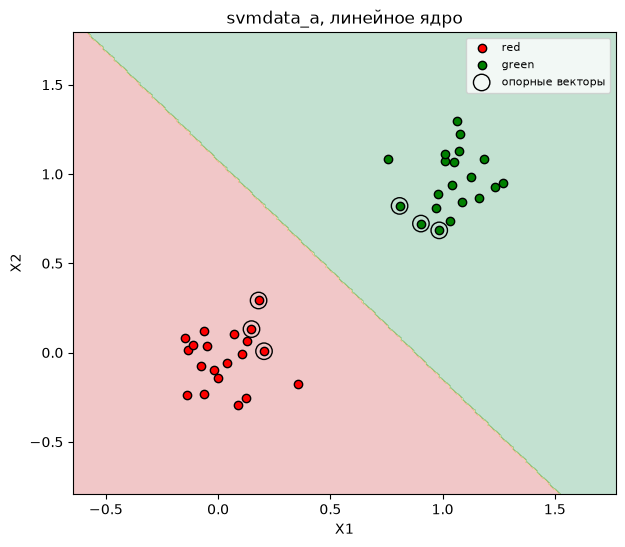

In [108]:
Xa, ya = load_svm('svmdata_a.txt')
Xa_te, ya_te = load_svm('svmdata_a_test.txt')

svm_a = SVC(kernel='linear', C=1).fit(Xa, ya)

print('Опорных векторов (red, green):', svm_a.n_support_)
print('Матрица ошибок train:\n', confusion_matrix(ya, svm_a.predict(Xa)))
print('Матрица ошибок test:\n', confusion_matrix(ya_te, svm_a.predict(Xa_te)))

plt.figure(figsize=(7, 6))
plot_svm(svm_a, Xa, ya, 'svmdata_a, линейное ядро')
plt.show()

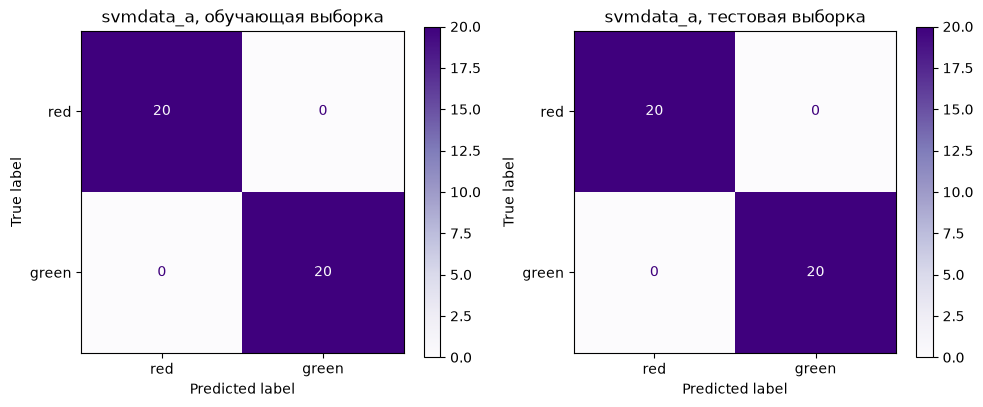

In [109]:
# Матрицы ошибок svmdata_a
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(svm_a, Xa, ya, display_labels=['red', 'green'],
                                      cmap='Purples', ax=ax[0])
ax[0].set_title('svmdata_a, обучающая выборка')
ConfusionMatrixDisplay.from_estimator(svm_a, Xa_te, ya_te, display_labels=['red', 'green'],
                                      cmap='Purples', ax=ax[1])
ax[1].set_title('svmdata_a, тестовая выборка')
plt.tight_layout()
plt.show()

### 4b. svmdata_b: подбор штрафа C
C - штраф за ошибки на обучающей выборке. Малое C - широкая «мягкая» полоса, ошибки допускаются; большое C - модель любой ценой старается не ошибаться на обучающей выборке.

In [110]:
Xb, yb = load_svm('svmdata_b.txt')
Xb_te, yb_te = load_svm('svmdata_b_test.txt')

rows = []
for C in [0.01, 0.1, 1, 10, 100, 500, 1000]:
    m = SVC(kernel='linear', C=C).fit(Xb, yb)
    rows.append({'C': C,
                 'ошибок train': (m.predict(Xb) != yb).sum(),
                 'ошибок test': (m.predict(Xb_te) != yb_te).sum(),
                 'опорных векторов': len(m.support_vectors_)})
pd.DataFrame(rows)

,C,ошибок train,ошибок test,опорных векторов
0,0.01,1,0,50
1,0.10,1,0,28
2,1.00,1,0,11
3,10.00,1,0,4
4,100.00,1,0,4
5,500.00,0,3,3
6,1000.00,0,3,3


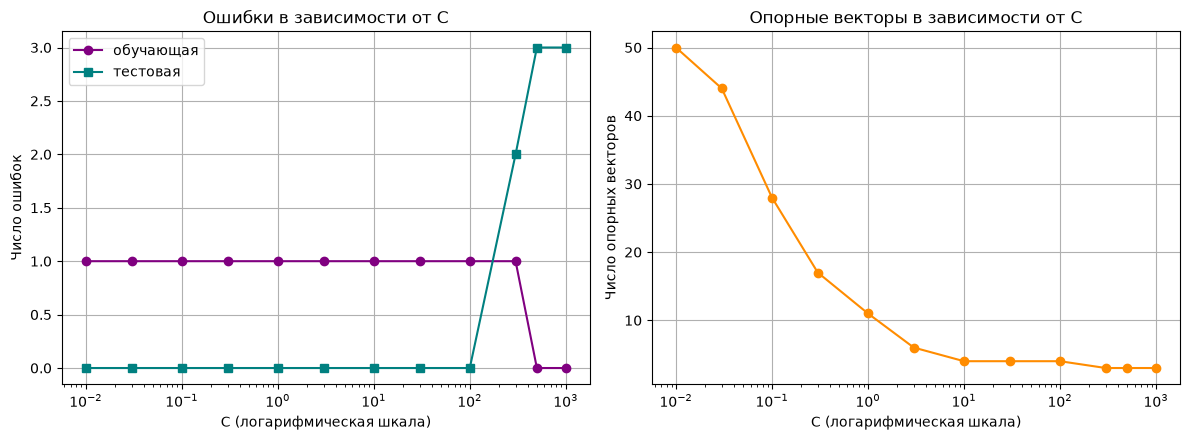

In [111]:
# Число ошибок и опорных векторов в зависимости от C (svmdata_b)
Cs = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 500, 1000]
e_tr, e_te, n_sv = [], [], []
for C in Cs:
    m = SVC(kernel='linear', C=C).fit(Xb, yb)
    e_tr.append((m.predict(Xb) != yb).sum())
    e_te.append((m.predict(Xb_te) != yb_te).sum())
    n_sv.append(len(m.support_vectors_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(Cs, e_tr, marker='o', color='purple', label='обучающая')
ax[0].plot(Cs, e_te, marker='s', color='teal', label='тестовая')
ax[0].set_xscale('log')
ax[0].set_xlabel('C (логарифмическая шкала)')
ax[0].set_ylabel('Число ошибок')
ax[0].set_title('Ошибки в зависимости от C')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(Cs, n_sv, marker='o', color='darkorange')
ax[1].set_xscale('log')
ax[1].set_xlabel('C (логарифмическая шкала)')
ax[1].set_ylabel('Число опорных векторов')
ax[1].set_title('Опорные векторы в зависимости от C')
ax[1].grid(True)
plt.tight_layout()
plt.show()

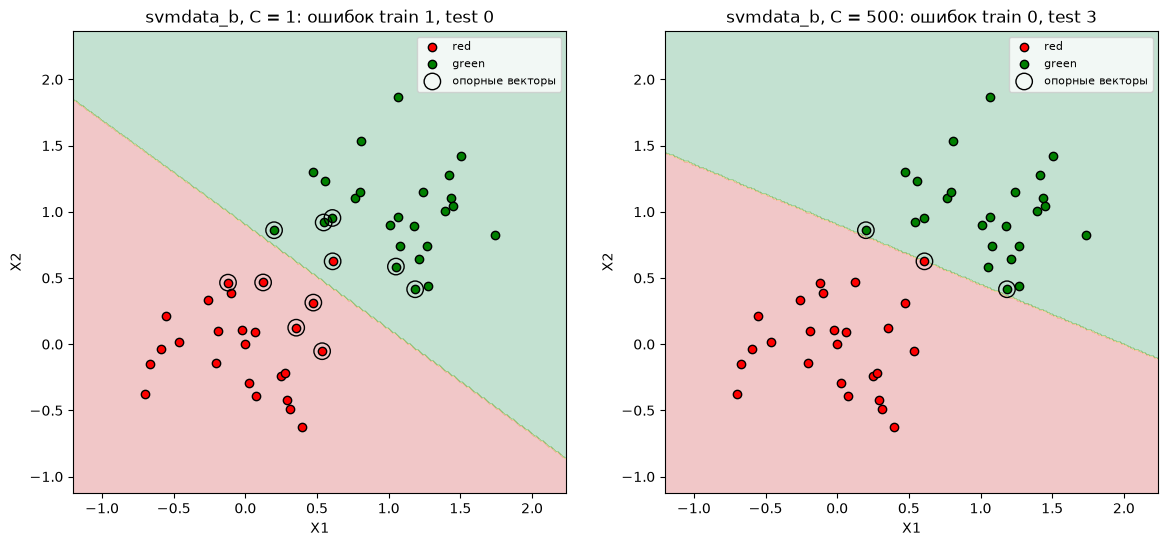

In [112]:
plt.figure(figsize=(14, 6))
for i, C in enumerate([1, 500]):
    m = SVC(kernel='linear', C=C).fit(Xb, yb)
    plt.subplot(1, 2, i + 1)
    plot_svm(m, Xb, yb, f'svmdata_b, C = {C}: ошибок train {(m.predict(Xb) != yb).sum()}, test {(m.predict(Xb_te) != yb_te).sum()}')
plt.show()

### Выводы по заданию 4a–4b
для svmdata_a хватает линейного ядра: классы линейно разделимы, ошибок нет ни на обучающей, ни на тестовой выборке. Граница опирается всего на 6 опорных векторов; остальные 34 точки можно удалить, и решение не изменится.


на svmdata_b лучше работает небольшой штраф C = 1, чем максимальный. Без ошибок на тестовой выборке модель работает уже при C = 0.01, а без ошибок на обучающей - только при C = 500, и тогда на тесте появляются 3 ошибки.

### 4c. svmdata_c: сравнение ядер

In [113]:
kernels = {'линейное': dict(kernel='linear'),
           'полином d=1': dict(kernel='poly', degree=1, coef0=1),
           'полином d=2': dict(kernel='poly', degree=2, coef0=1),
           'полином d=3': dict(kernel='poly', degree=3, coef0=1),
           'полином d=4': dict(kernel='poly', degree=4, coef0=1),
           'полином d=5': dict(kernel='poly', degree=5, coef0=1),
           'сигмоида': dict(kernel='sigmoid'),
           'гауссово (rbf)': dict(kernel='rbf')}

def compare_kernels(name, kernels):
    X, y = load_svm(f'svmdata_{name}.txt')
    X_te, y_te = load_svm(f'svmdata_{name}_test.txt')
    plt.figure(figsize=(18, 8))
    for i, (kname, params) in enumerate(kernels.items()):
        m = SVC(**params).fit(X, y)
        plt.subplot(2, 4, i + 1)
        plot_svm(m, X, y, f'{kname}: train {m.score(X, y):.2f}, test {m.score(X_te, y_te):.2f}')
    plt.tight_layout()
    plt.show()

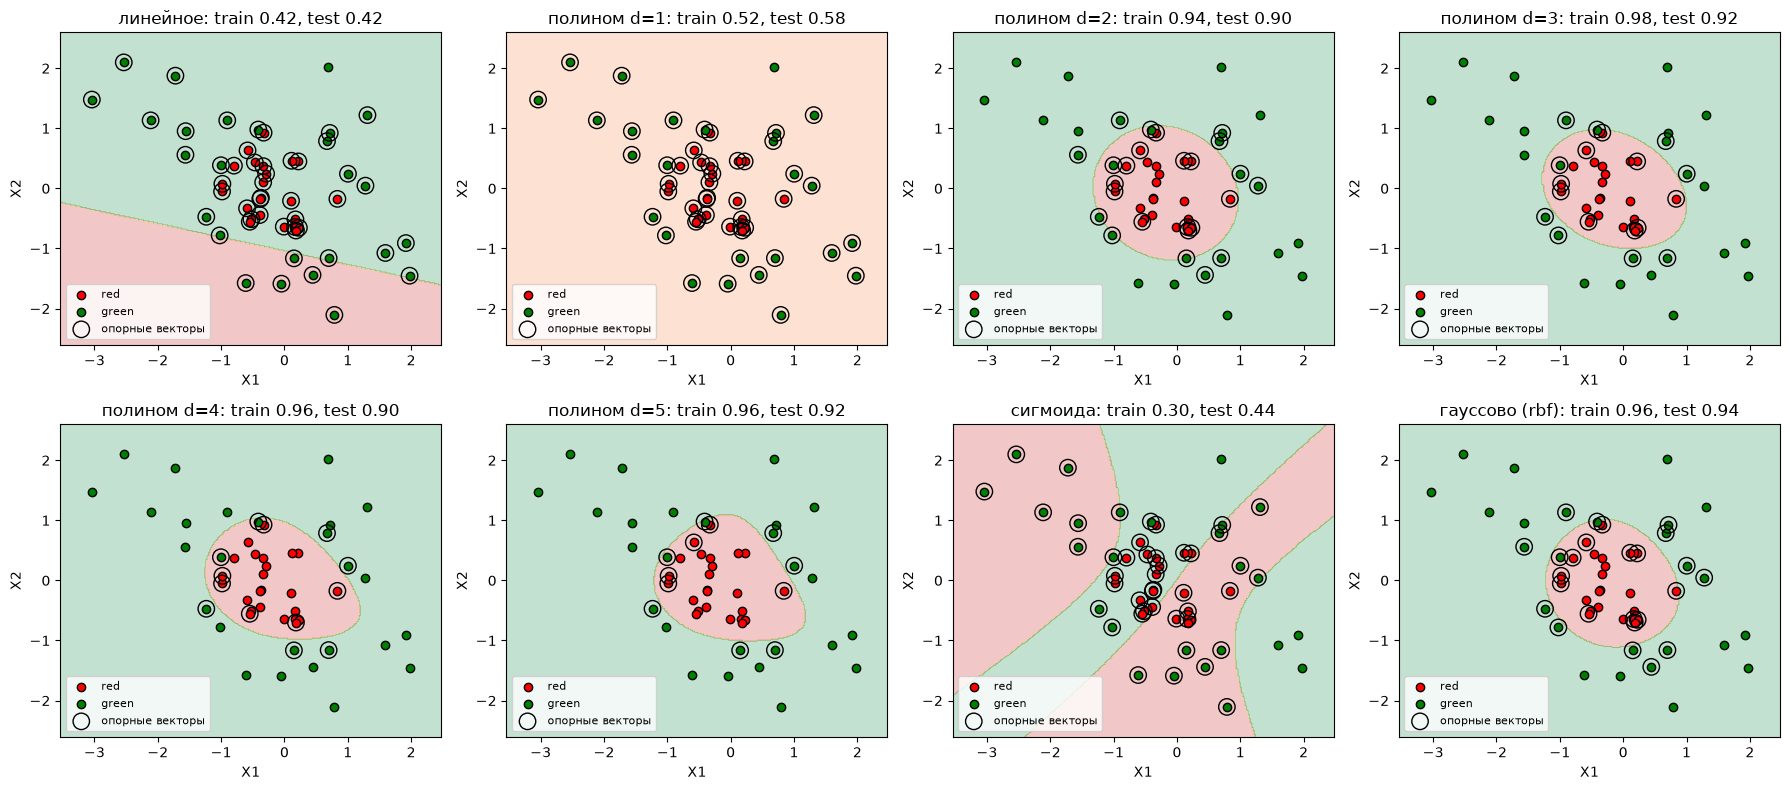

In [114]:
compare_kernels('c', kernels)

In [115]:
# Таблица по ядрам: accuracy и число опорных векторов
def kernel_table(name, kernels):
    X, y = load_svm(f'svmdata_{name}.txt')
    X_te, y_te = load_svm(f'svmdata_{name}_test.txt')
    rows_k = []
    for kname, params in kernels.items():
        m = SVC(**params).fit(X, y)
        rows_k.append({'ядро': kname,
                       'accuracy train': round(m.score(X, y), 3),
                       'accuracy test': round(m.score(X_te, y_te), 3),
                       'опорных векторов': len(m.support_vectors_)})
    return pd.DataFrame(rows_k)

kernel_table('c', kernels)

,ядро,accuracy train,accuracy test,опорных векторов
0,линейное,0.42,0.42,49
1,полином d=1,0.52,0.58,49
2,полином d=2,0.94,0.90,25
3,полином d=3,0.98,0.92,18
4,полином d=4,0.96,0.90,13
5,полином d=5,0.96,0.92,12
6,сигмоида,0.30,0.44,44
7,гауссово (rbf),0.96,0.94,25


### 4d. svmdata_d: сравнение ядер (без линейного)

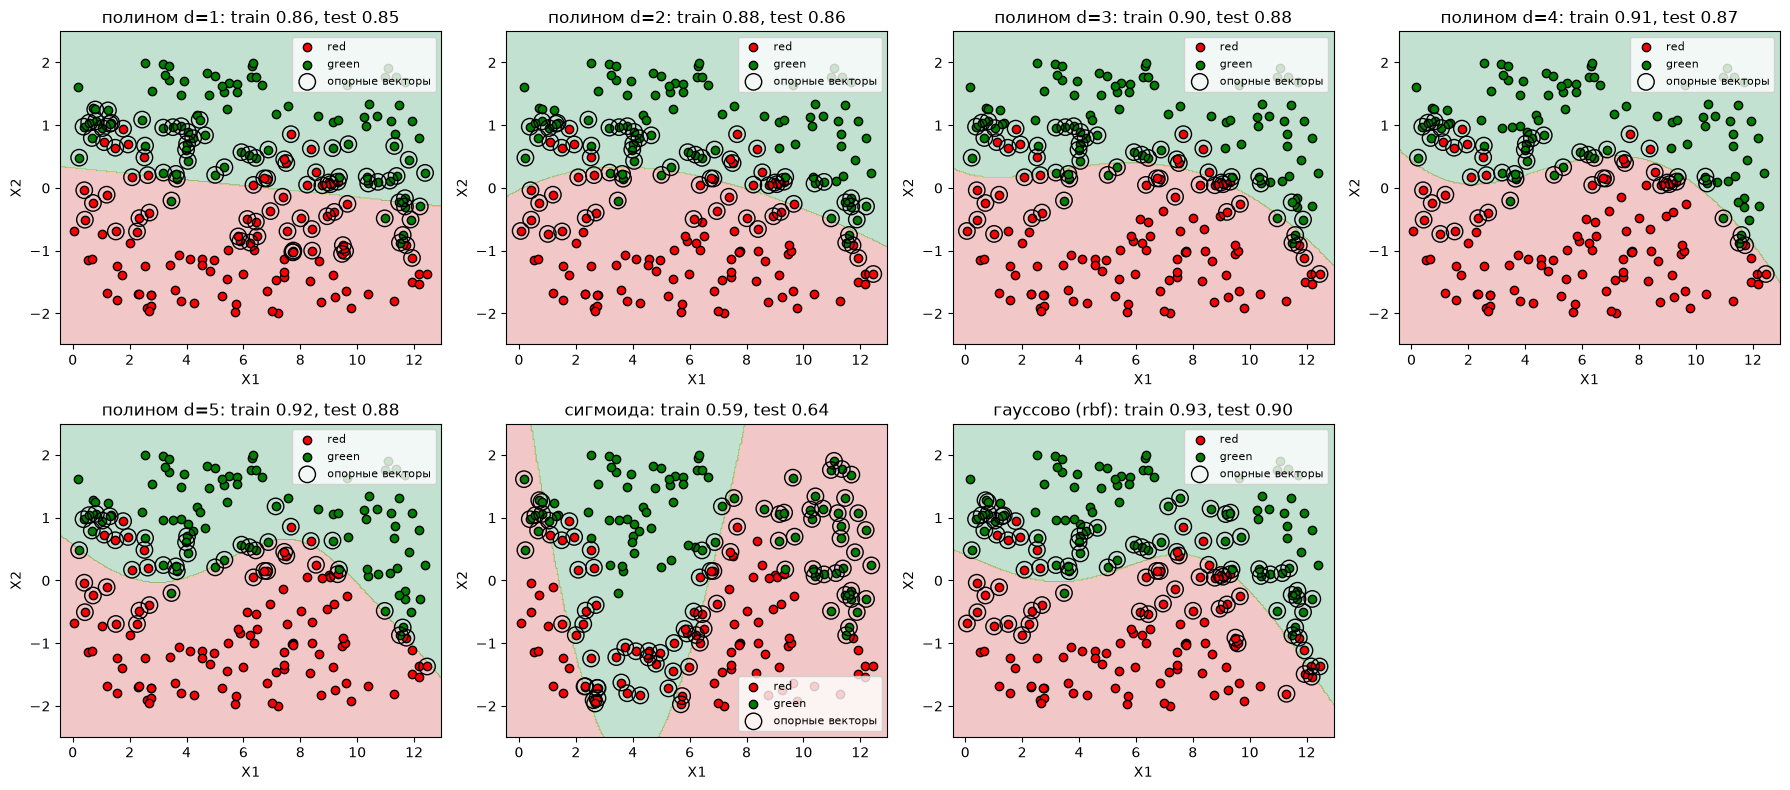

In [116]:
kernels_no_linear = {k: v for k, v in kernels.items() if k != 'линейное'}
compare_kernels('d', kernels_no_linear)

In [117]:
kernel_table('d', kernels_no_linear)

,ядро,accuracy train,accuracy test,опорных векторов
0,полином d=1,0.865,0.850,102
1,полином d=2,0.875,0.865,79
2,полином d=3,0.900,0.875,68
3,полином d=4,0.910,0.870,57
4,полином d=5,0.915,0.880,53
5,сигмоида,0.590,0.640,98
6,гауссово (rbf),0.925,0.895,95


### 4e. svmdata_e: сравнение ядер (без линейного)

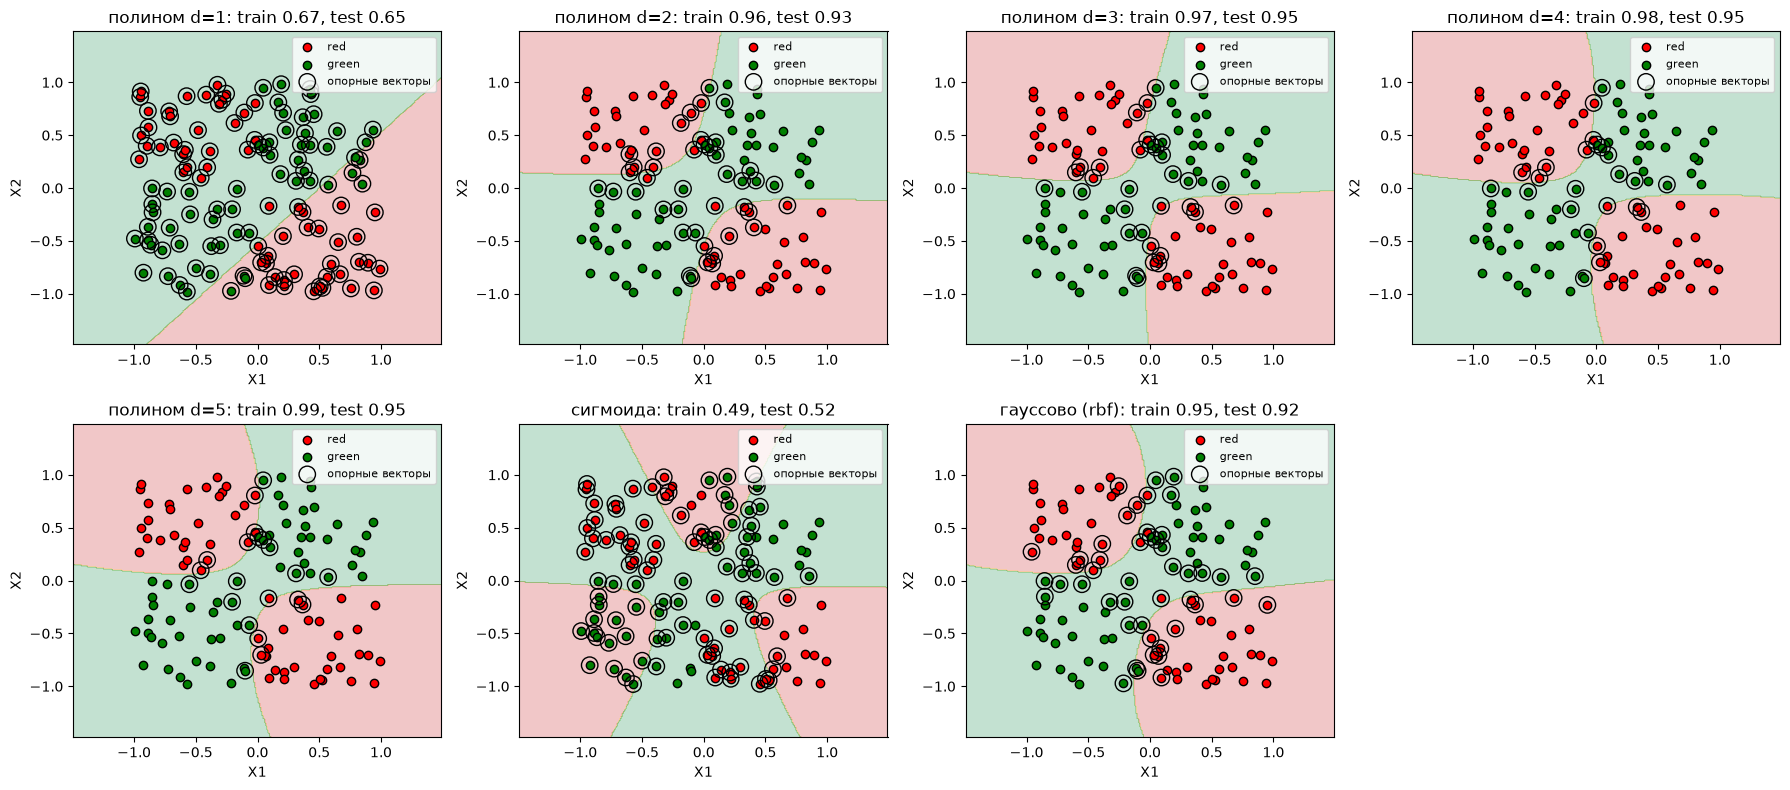

In [118]:
compare_kernels('e', kernels_no_linear)

In [119]:
kernel_table('e', kernels_no_linear)

,ядро,accuracy train,accuracy test,опорных векторов
0,полином d=1,0.667,0.650,120
1,полином d=2,0.958,0.925,42
2,полином d=3,0.975,0.950,32
3,полином d=4,0.983,0.950,24
4,полином d=5,0.992,0.950,21
5,сигмоида,0.492,0.517,96
6,гауссово (rbf),0.950,0.917,47


### Параметр gamma гауссова ядра (svmdata_e)
gamma задаёт, насколько далеко «дотягивается» влияние одной точки: малое gamma - влияние широкое, граница гладкая; большое - каждая точка влияет только на маленькую область вокруг себя.

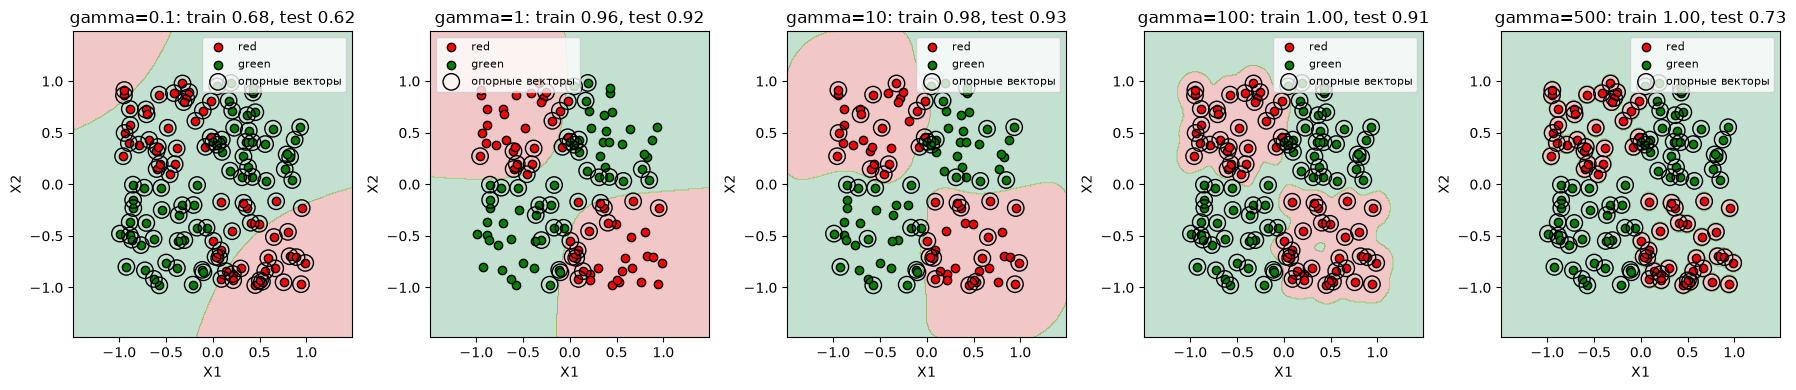

In [120]:
Xe, ye = load_svm('svmdata_e.txt')
Xe_te, ye_te = load_svm('svmdata_e_test.txt')

plt.figure(figsize=(18, 4))
for i, g in enumerate([0.1, 1, 10, 100, 500]):
    m = SVC(kernel='rbf', gamma=g).fit(Xe, ye)
    plt.subplot(1, 5, i + 1)
    plot_svm(m, Xe, ye, f'gamma={g}: train {m.score(Xe, ye):.2f}, test {m.score(Xe_te, ye_te):.2f}')
plt.tight_layout()
plt.show()

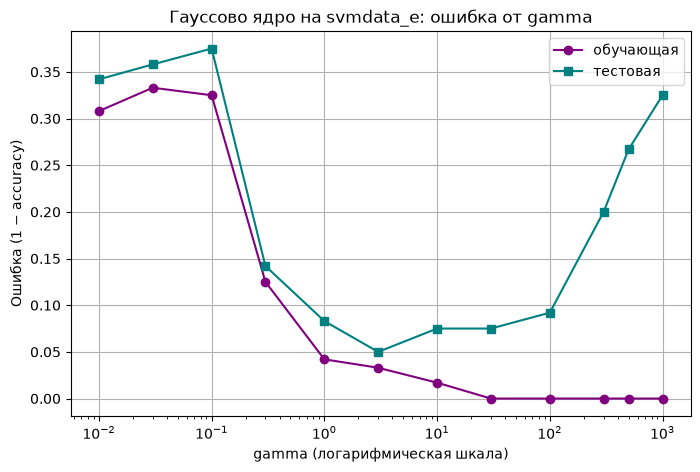

,gamma,ошибка train,ошибка test,опорных векторов
0,0.01,0.308,0.342,120
1,0.03,0.333,0.358,120
2,0.10,0.325,0.375,120
3,0.30,0.125,0.142,85
4,1.00,0.042,0.083,53
5,3.00,0.033,0.050,46
6,10.00,0.017,0.075,53
7,30.00,0.000,0.075,93
8,100.00,0.000,0.092,117
9,300.00,0.000,0.200,120


In [121]:
# Ошибка гауссова ядра в зависимости от gamma (svmdata_e)
gammas = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 500, 1000]
g_rows = []
for g in gammas:
    m = SVC(kernel='rbf', gamma=g).fit(Xe, ye)
    g_rows.append({'gamma': g,
                   'ошибка train': round(1 - m.score(Xe, ye), 3),
                   'ошибка test': round(1 - m.score(Xe_te, ye_te), 3),
                   'опорных векторов': len(m.support_vectors_)})
g_tab = pd.DataFrame(g_rows)

plt.figure(figsize=(8, 5))
plt.plot(gammas, g_tab['ошибка train'], marker='o', color='purple', label='обучающая')
plt.plot(gammas, g_tab['ошибка test'], marker='s', color='teal', label='тестовая')
plt.xscale('log')
plt.xlabel('gamma (логарифмическая шкала)')
plt.ylabel('Ошибка (1 − accuracy)')
plt.title('Гауссово ядро на svmdata_e: ошибка от gamma')
plt.legend()
plt.grid(True)
plt.show()
g_tab

### Параметр gamma для всех ядер (svmdata_e)
В задании 4e требуется менять gamma для разных ядер. Для полиномиального и сигмоидального ядер gamma - множитель перед скалярным произведением: (gamma·⟨x, x′⟩ + 1)^d и tanh(gamma·⟨x, x′⟩).

In [122]:
# Параметр gamma для всех ядер: полиномиальные степени 1–5, сигмоида, гауссово (svmdata_e)
gammas_all = [0.1, 1, 10, 100]
kern_g = {f'полином d={d}': dict(kernel='poly', degree=d, coef0=1) for d in range(1, 6)}
kern_g['сигмоида'] = dict(kernel='sigmoid')
kern_g['гауссово (rbf)'] = dict(kernel='rbf')

g_all = []
for kname, params in kern_g.items():
    for g in gammas_all:
        m = SVC(gamma=g, max_iter=100000, **params).fit(Xe, ye)
        g_all.append({'ядро': kname, 'gamma': g,
                      'accuracy train': round(m.score(Xe, ye), 3),
                      'accuracy test': round(m.score(Xe_te, ye_te), 3),
                      'опорных векторов': len(m.support_vectors_)})
g_all = pd.DataFrame(g_all)
g_all

,ядро,gamma,accuracy train,accuracy test,опорных векторов
0,полином d=1,0.1,0.675,0.642,120
1,полином d=1,1.0,0.667,0.650,120
2,полином d=1,10.0,0.667,0.625,119
3,полином d=1,100.0,0.667,0.625,119
4,полином d=2,0.1,0.667,0.642,120
5,полином d=2,1.0,0.958,0.942,50
6,полином d=2,10.0,1.000,0.975,14
7,полином d=2,100.0,1.000,0.967,5
8,полином d=3,0.1,0.767,0.742,116
9,полином d=3,1.0,0.958,0.933,39


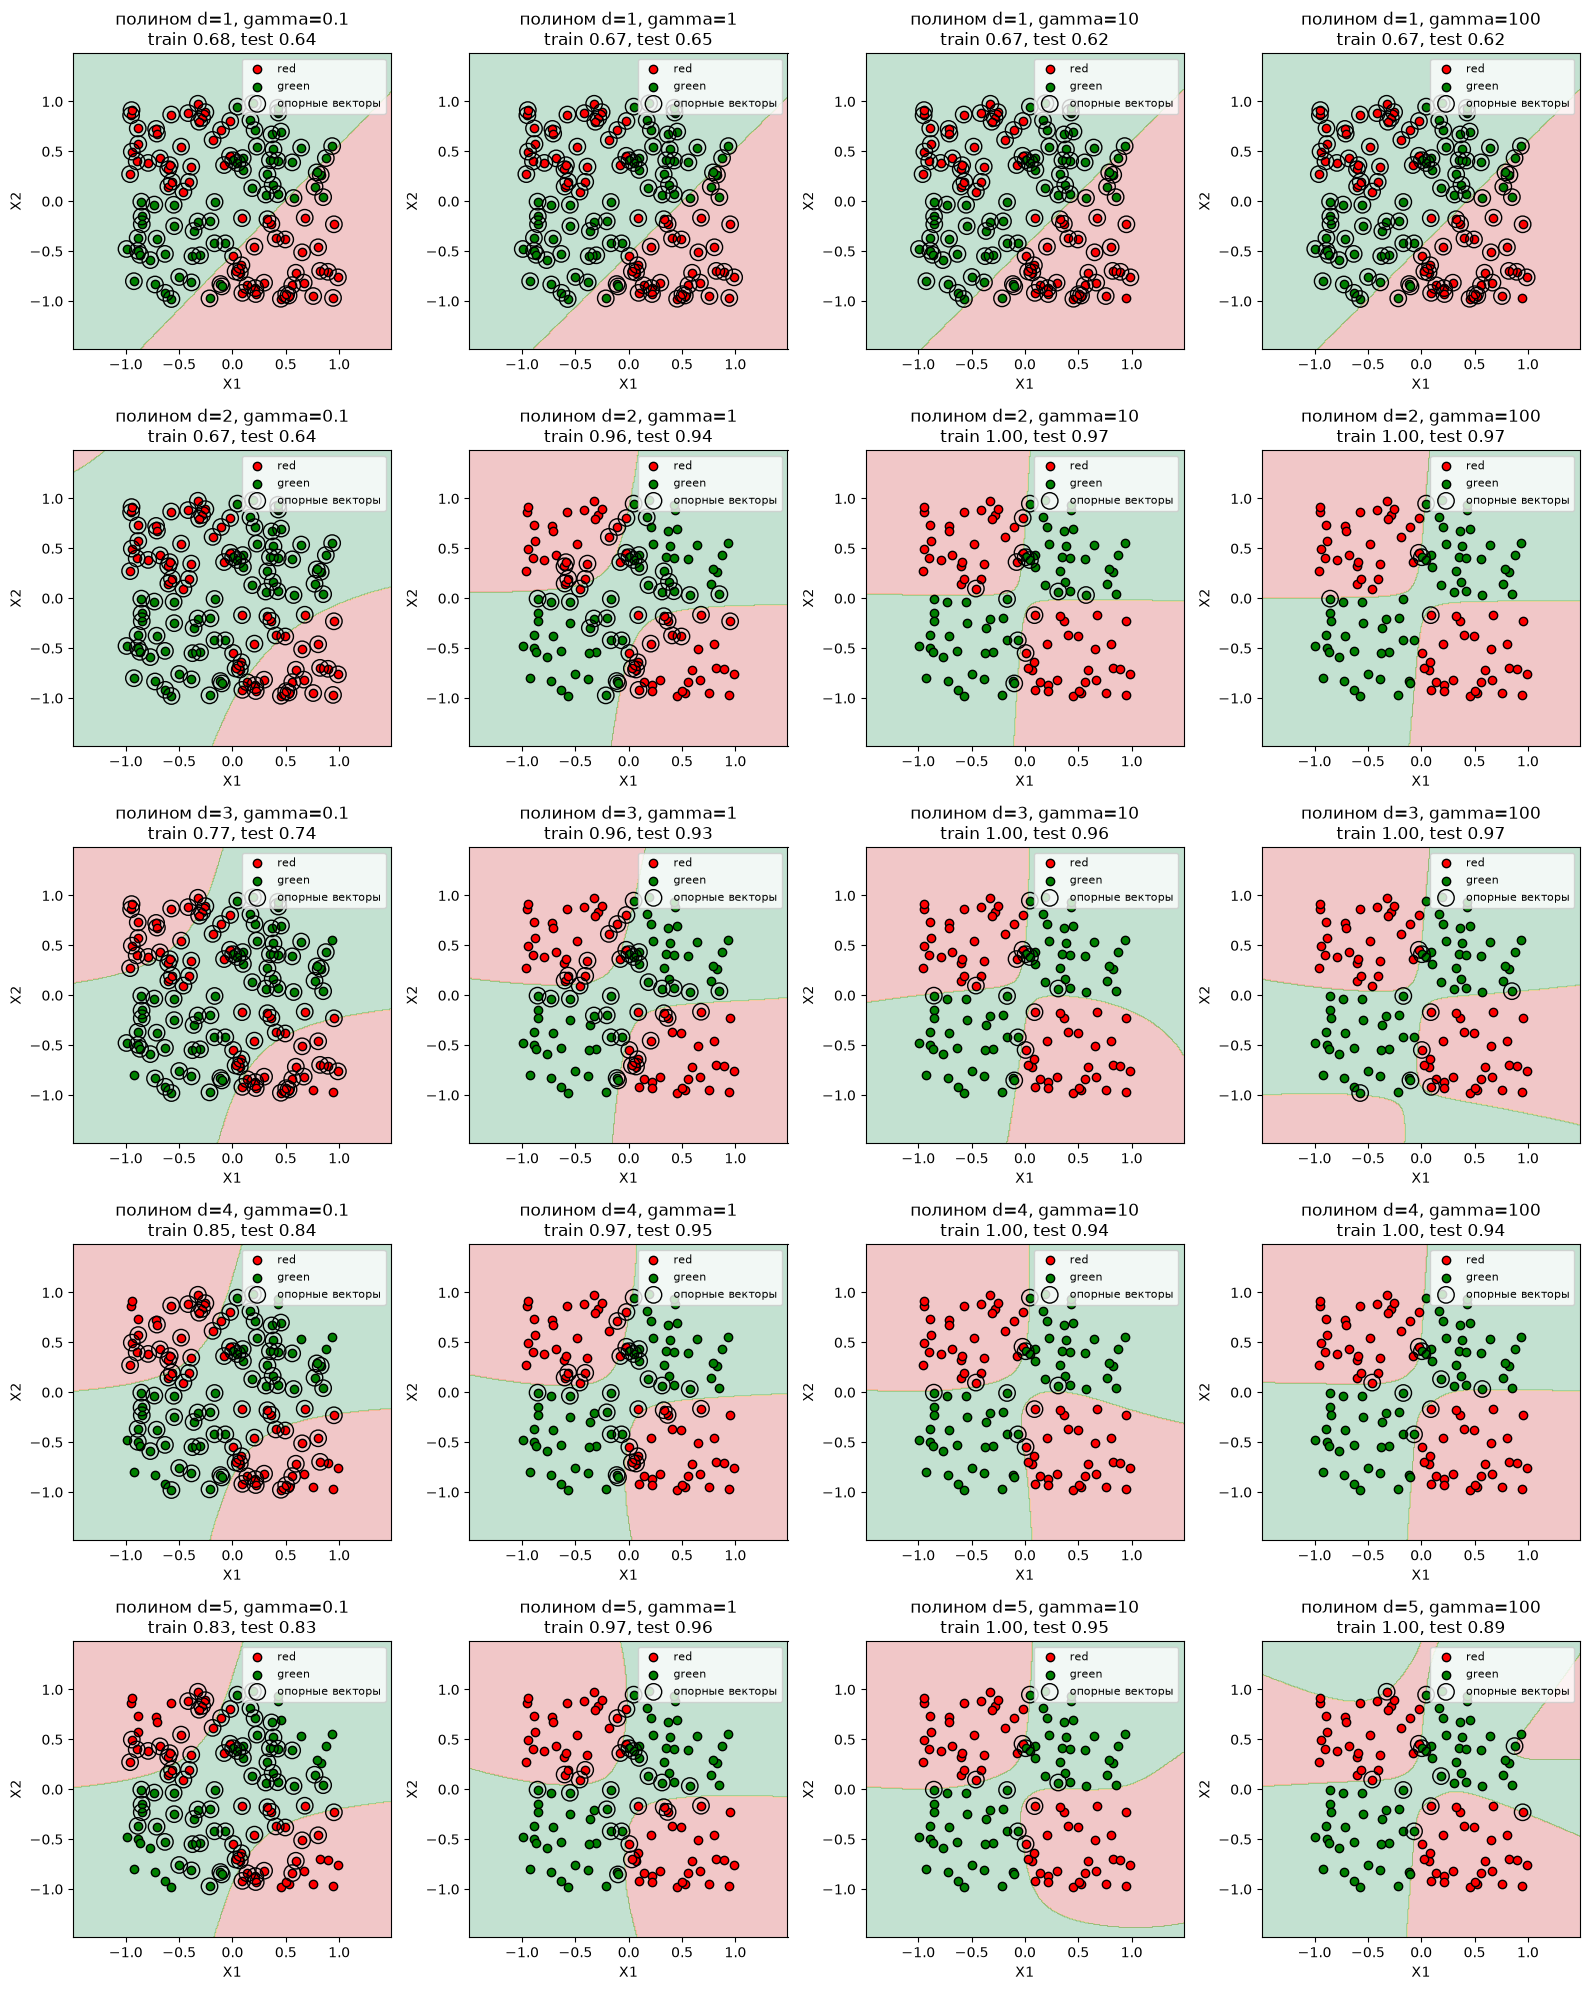

In [123]:
# Области классов: полиномиальные ядра степеней 1–5 при разных gamma
def gamma_grid(kernel_names):
    plt.figure(figsize=(16, 4 * len(kernel_names)))
    for r, kname in enumerate(kernel_names):
        for c, g in enumerate(gammas_all):
            m = SVC(gamma=g, max_iter=100000, **kern_g[kname]).fit(Xe, ye)
            plt.subplot(len(kernel_names), len(gammas_all), r * len(gammas_all) + c + 1)
            plot_svm(m, Xe, ye, f'{kname}, gamma={g}\ntrain {m.score(Xe, ye):.2f}, test {m.score(Xe_te, ye_te):.2f}')
    plt.tight_layout()
    plt.show()

gamma_grid([f'полином d={d}' for d in range(1, 6)])

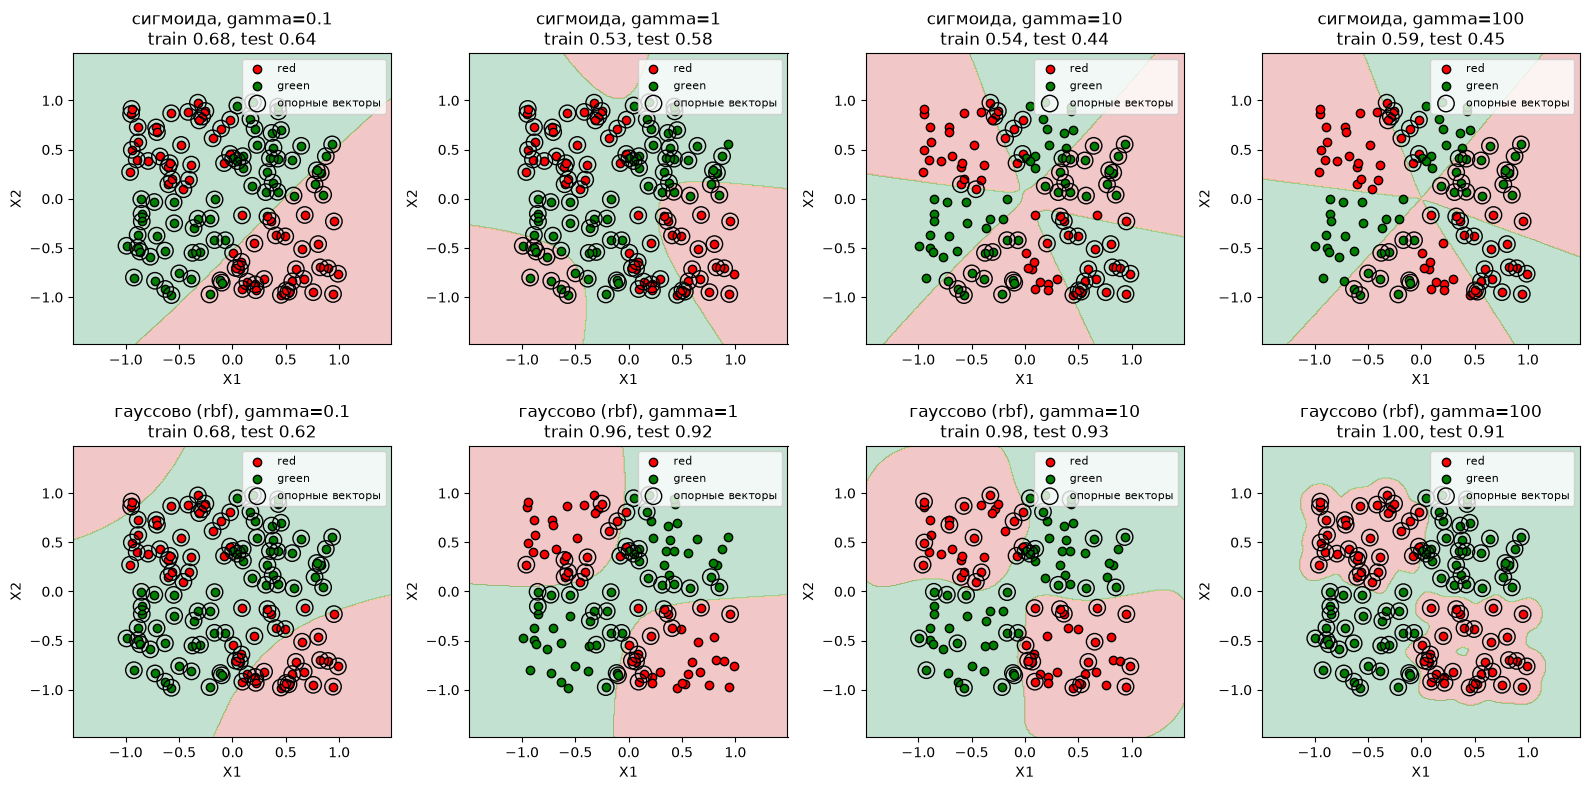

In [124]:
# Области классов: сигмоидальное и гауссово ядра при тех же gamma
gamma_grid(['сигмоида', 'гауссово (rbf)'])

### Выводы по заданию 4c–4e
для svmdata_c линейного и сигмоидального ядер недостаточно. Полиномиальное ядро работает начиная со степени 2, когда граница может стать замкнутой кривой. Лучше всего подходит гауссово ядро: оно измеряет сходство через расстояние между точками и естественно строит «островок» вокруг компактного облака red.


на svmdata_d хорошо работает уже низкая степень полинома, а рост степени даёт небольшой выигрыш. Гауссово ядро снова лучше полиномиального, сигмоидальное не подходит.


подбирать gamma нужно по ошибке на тестовой выборке: идеальная точность на обучающей выборке как раз и означает переобучение. Переобучение при большом gamma хорошо видно у гауссова ядра и у полинома высокой степени (точность на обучающей выборке 1.000 при падающей точности на тесте). Полином степени 1 и сигмоидальное ядро на этих данных слабые при любом gamma; среди полиномов имеют смысл степени 2–5 при gamma около 1. Число опорных векторов - хороший индикатор: у подходящей модели их мало, у недообученной и у переобученной почти все точки становятся опорными.

## Задание 5. Деревья решений
### 5a. Glass

Глубина: 11  листьев: 38
accuracy train: 1.0  test: 0.738


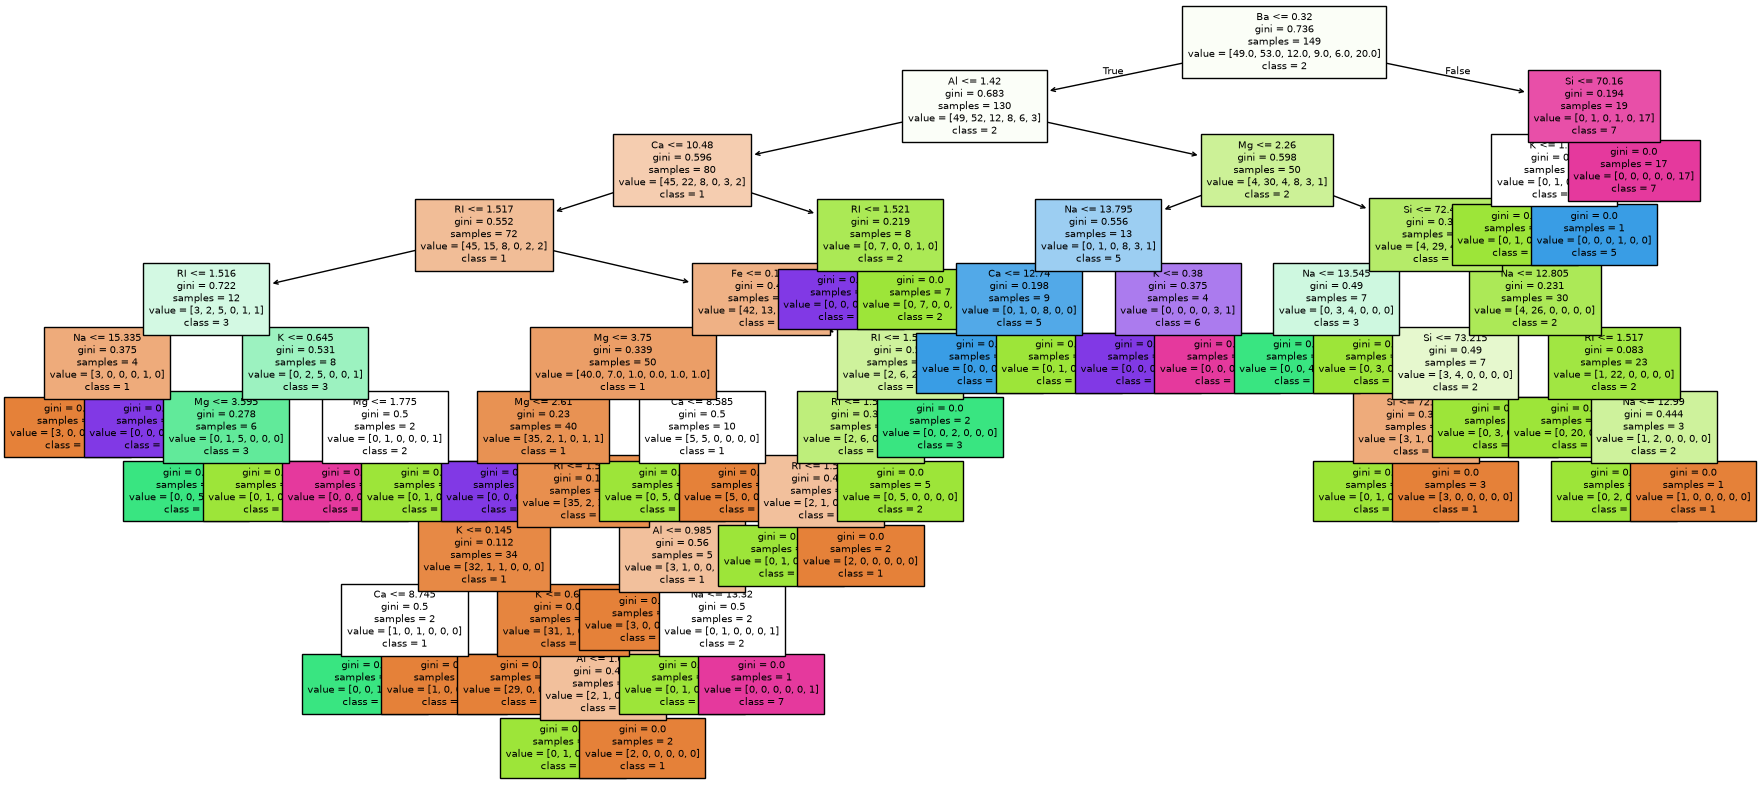

In [125]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(random_state=42).fit(X3_train, y3_train)
print('Глубина:', tree.get_depth(), ' листьев:', tree.get_n_leaves())
print('accuracy train:', tree.score(X3_train, y3_train), ' test:', round(tree.score(X3_test, y3_test), 3))

plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=list(X3.columns), class_names=[str(c) for c in tree.classes_],
          filled=True, fontsize=7)
plt.show()

In [126]:
# Полное дерево: сравнение критериев gini и entropy
rows_c = []
for crit in ['gini', 'entropy']:
    t = DecisionTreeClassifier(criterion=crit, random_state=42).fit(X3_train, y3_train)
    rows_c.append({'критерий': crit,
                   'глубина': t.get_depth(),
                   'листьев': t.get_n_leaves(),
                   'accuracy train': round(t.score(X3_train, y3_train), 3),
                   'accuracy test': round(t.score(X3_test, y3_test), 3)})
pd.DataFrame(rows_c)

,критерий,глубина,листьев,accuracy train,accuracy test
0,gini,11,38,1.0,0.738
1,entropy,8,34,1.0,0.769


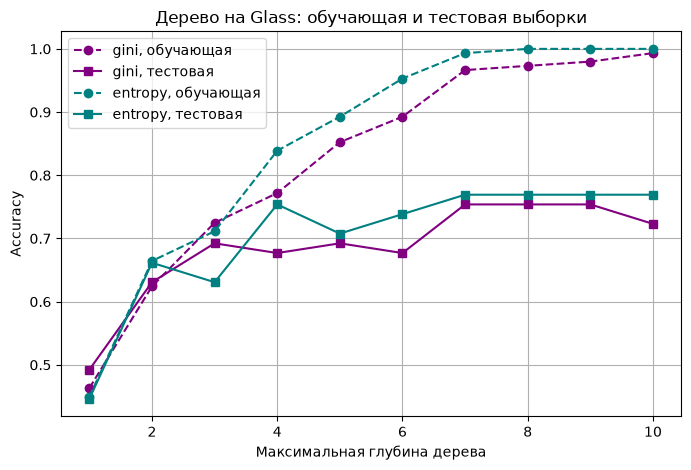

train           test       
критерий entropy   gini entropy   gini
глубина                               
1          0.450  0.463   0.446  0.492
2          0.664  0.624   0.662  0.631
3          0.711  0.725   0.631  0.692
4          0.839  0.772   0.754  0.677
5          0.893  0.852   0.708  0.692
6          0.953  0.893   0.738  0.677
7          0.993  0.966   0.769  0.754
8          1.000  0.973   0.769  0.754
9          1.000  0.980   0.769  0.754
10         1.000  0.993   0.769  0.723

In [127]:
# Глубина дерева: accuracy на обучающей и тестовой выборках
depths = range(1, 11)
depth_rows = []
for crit in ['gini', 'entropy']:
    for d in depths:
        t = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42).fit(X3_train, y3_train)
        depth_rows.append({'критерий': crit, 'глубина': d,
                           'train': t.score(X3_train, y3_train),
                           'test': t.score(X3_test, y3_test)})
depth_tab = pd.DataFrame(depth_rows)

plt.figure(figsize=(8, 5))
for crit, color in [('gini', 'purple'), ('entropy', 'teal')]:
    part = depth_tab[depth_tab['критерий'] == crit]
    plt.plot(part['глубина'], part['train'], linestyle='--', marker='o', color=color, label=f'{crit}, обучающая')
    plt.plot(part['глубина'], part['test'], marker='s', color=color, label=f'{crit}, тестовая')
plt.xlabel('Максимальная глубина дерева')
plt.ylabel('Accuracy')
plt.title('Дерево на Glass: обучающая и тестовая выборки')
plt.legend()
plt.grid(True)
plt.show()

depth_tab.pivot(index='глубина', columns='критерий', values=['train', 'test']).round(3)

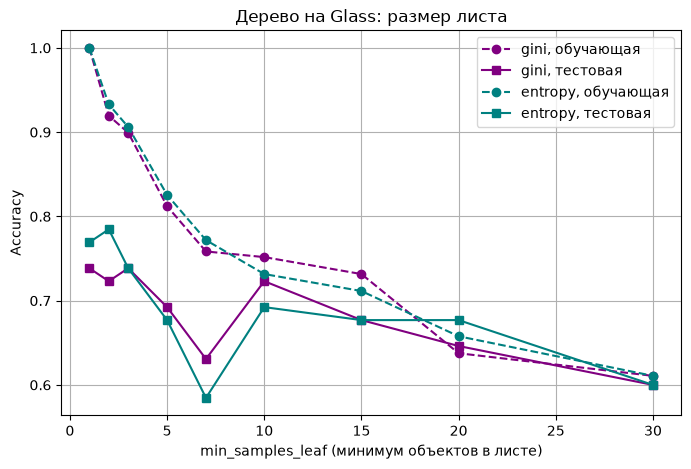

листьев         train           test       
критерий         entropy  gini entropy   gini entropy   gini
min_samples_leaf                                            
1                   34.0  38.0   1.000  1.000   0.769  0.738
2                   29.0  31.0   0.933  0.919   0.785  0.723
3                   25.0  26.0   0.906  0.899   0.738  0.738
5                   20.0  18.0   0.826  0.812   0.677  0.692
7                   16.0  14.0   0.772  0.758   0.585  0.631
10                  12.0  11.0   0.732  0.752   0.692  0.723
15                   8.0   9.0   0.711  0.732   0.677  0.677
20                   5.0   6.0   0.658  0.638   0.677  0.646
30                   4.0   4.0   0.611  0.611   0.600  0.600

In [128]:
# Минимальное число объектов в листе (min_samples_leaf)
leaves = [1, 2, 3, 5, 7, 10, 15, 20, 30]
leaf_rows = []
for crit in ['gini', 'entropy']:
    for L in leaves:
        t = DecisionTreeClassifier(criterion=crit, min_samples_leaf=L, random_state=42).fit(X3_train, y3_train)
        leaf_rows.append({'критерий': crit, 'min_samples_leaf': L,
                          'листьев': t.get_n_leaves(),
                          'train': t.score(X3_train, y3_train),
                          'test': t.score(X3_test, y3_test)})
leaf_tab = pd.DataFrame(leaf_rows)

plt.figure(figsize=(8, 5))
for crit, color in [('gini', 'purple'), ('entropy', 'teal')]:
    part = leaf_tab[leaf_tab['критерий'] == crit]
    plt.plot(part['min_samples_leaf'], part['train'], linestyle='--', marker='o', color=color, label=f'{crit}, обучающая')
    plt.plot(part['min_samples_leaf'], part['test'], marker='s', color=color, label=f'{crit}, тестовая')
plt.xlabel('min_samples_leaf (минимум объектов в листе)')
plt.ylabel('Accuracy')
plt.title('Дерево на Glass: размер листа')
plt.legend()
plt.grid(True)
plt.show()

leaf_tab.pivot(index='min_samples_leaf', columns='критерий', values=['листьев', 'train', 'test']).round(3)

Листьев: 30  accuracy train: 0.966  test: 0.754


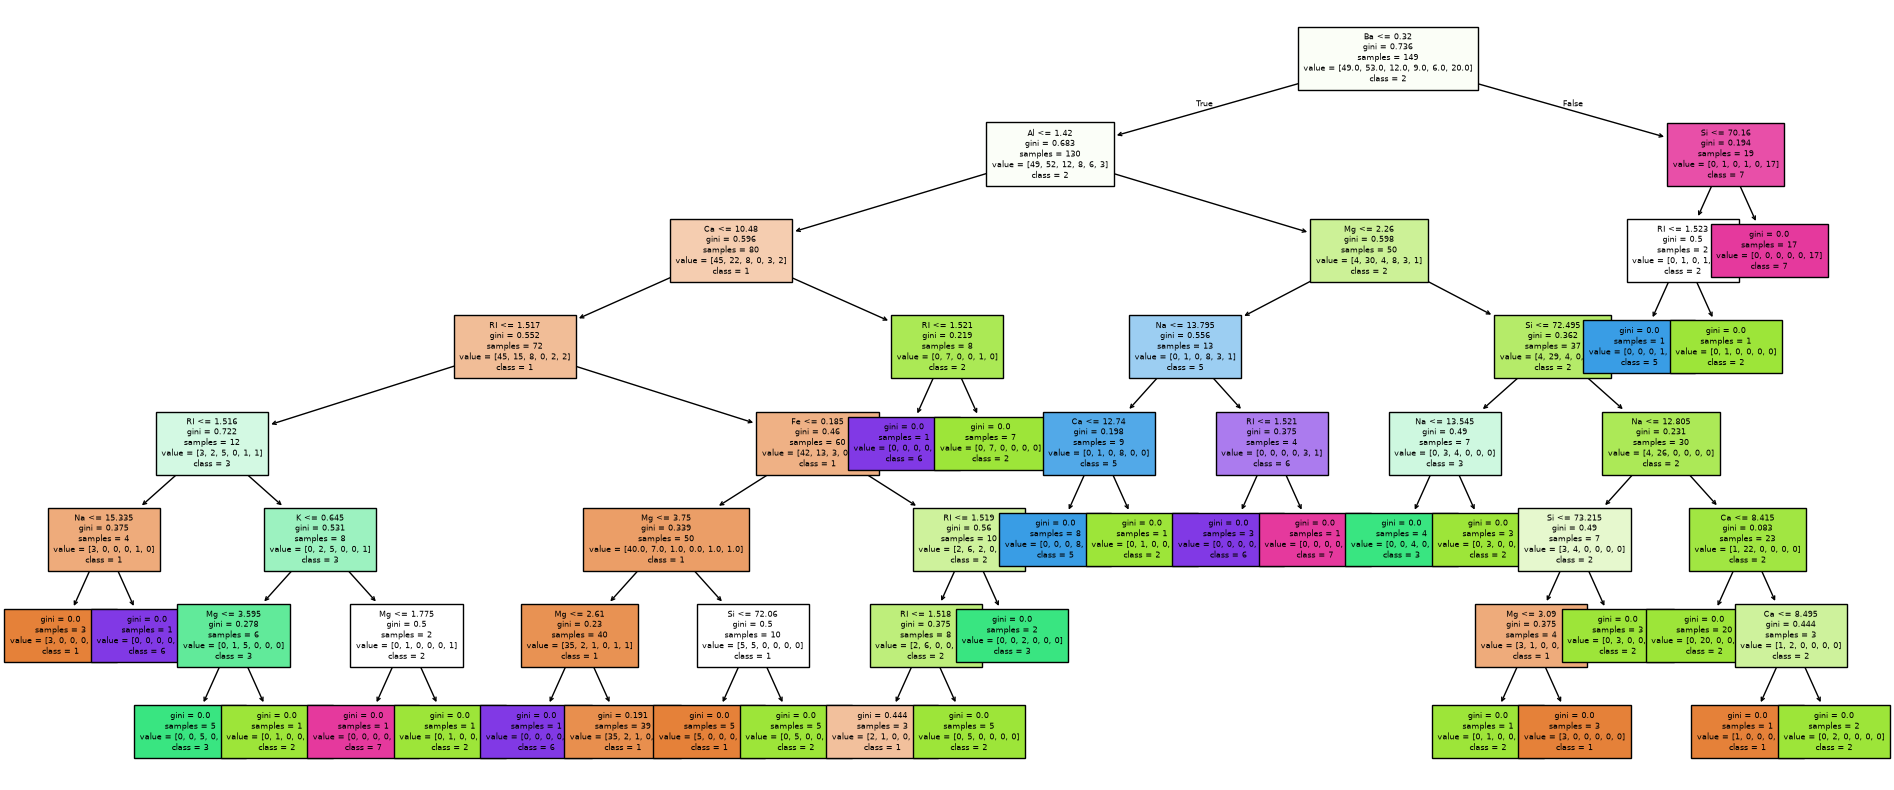

In [129]:
# Дерево с ограничением глубины 7 (gini)
tree7 = DecisionTreeClassifier(max_depth=7, random_state=42).fit(X3_train, y3_train)
print('Листьев:', tree7.get_n_leaves(), ' accuracy train:', round(tree7.score(X3_train, y3_train), 3),
      ' test:', round(tree7.score(X3_test, y3_test), 3))
plt.figure(figsize=(24, 10))
plot_tree(tree7, feature_names=list(X3.columns), class_names=[str(c) for c in tree7.classes_],
          filled=True, fontsize=6)
plt.show()

### Выводы по заданию 5a
дерево без ограничений для набора Glass избыточно: на обучающей выборке точность 1.0, на тестовой 0.738, дерево запоминает отдельные объекты. Ограничение глубины до 7 или минимального размера листа до 2 даёт такую же или лучшую точность на тесте (0.75–0.79) при меньшем дереве, а слишком сильное ограничение (глубина 1–3 или 20–30 объектов в листе) приводит к недообучению. Критерии gini и entropy дают близкие результаты, так как оба измеряют перемешанность классов в узле; на этих данных entropy немного лучше. Самые информативные признаки - Ba, Mg, Al и Ca: они отличают стекло фар, оконное стекло и тару.

### 5b. Spam7

Глубина: 29  листьев: 442  accuracy train: 0.975  test: 0.842


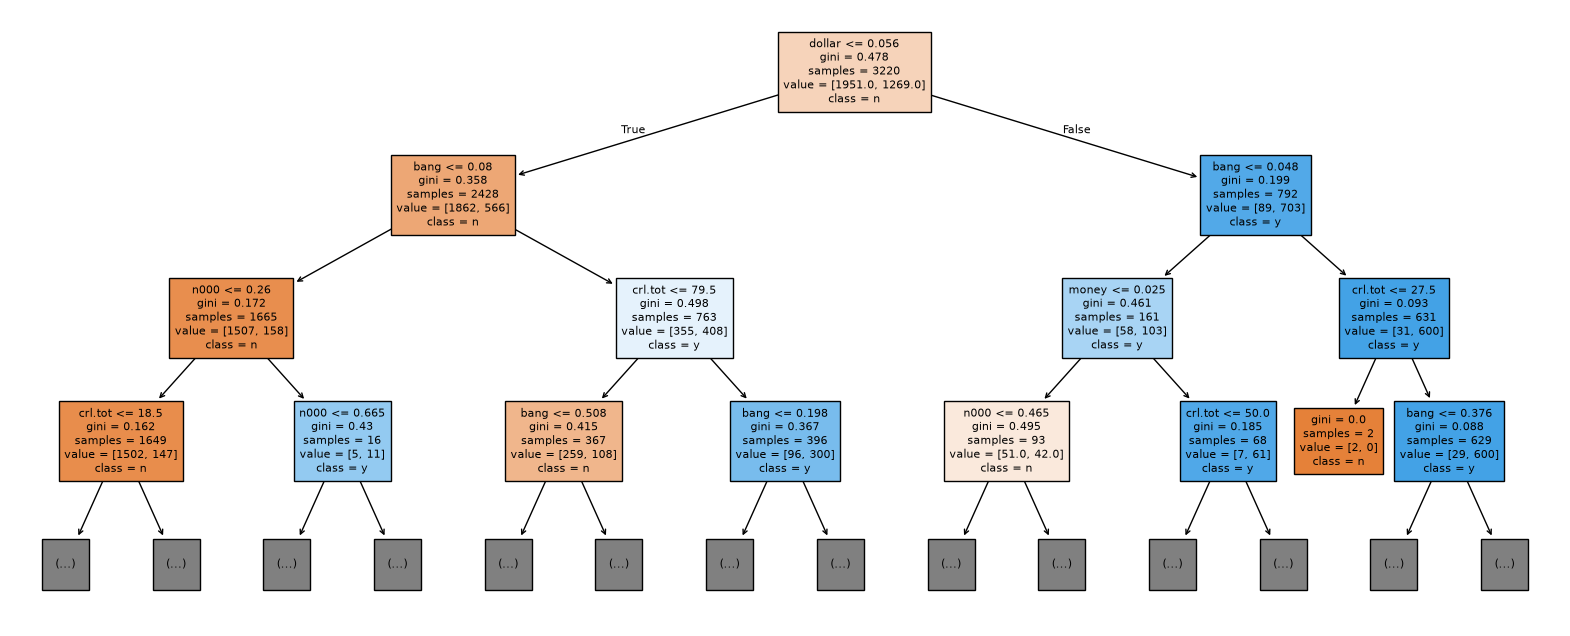

In [130]:
# spam7: дерево без ограничений
spam7 = pd.read_csv('spam7.csv')
X5 = spam7.drop(columns='yesno')
y5 = spam7['yesno']
X5_train, X5_test, y5_train, y5_test = train_test_split(X5, y5, test_size=0.3, random_state=42, stratify=y5)

full5 = DecisionTreeClassifier(random_state=42).fit(X5_train, y5_train)
print('Глубина:', full5.get_depth(), ' листьев:', full5.get_n_leaves(),
      ' accuracy train:', round(full5.score(X5_train, y5_train), 3), ' test:', round(full5.score(X5_test, y5_test), 3))
plt.figure(figsize=(20, 8))
plot_tree(full5, feature_names=list(X5.columns), class_names=list(full5.classes_),
          filled=True, max_depth=3, fontsize=8)
plt.show()

Лучшие параметры: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 20}
accuracy CV: 0.873  test: 0.865
[[777  60]
 [126 418]]


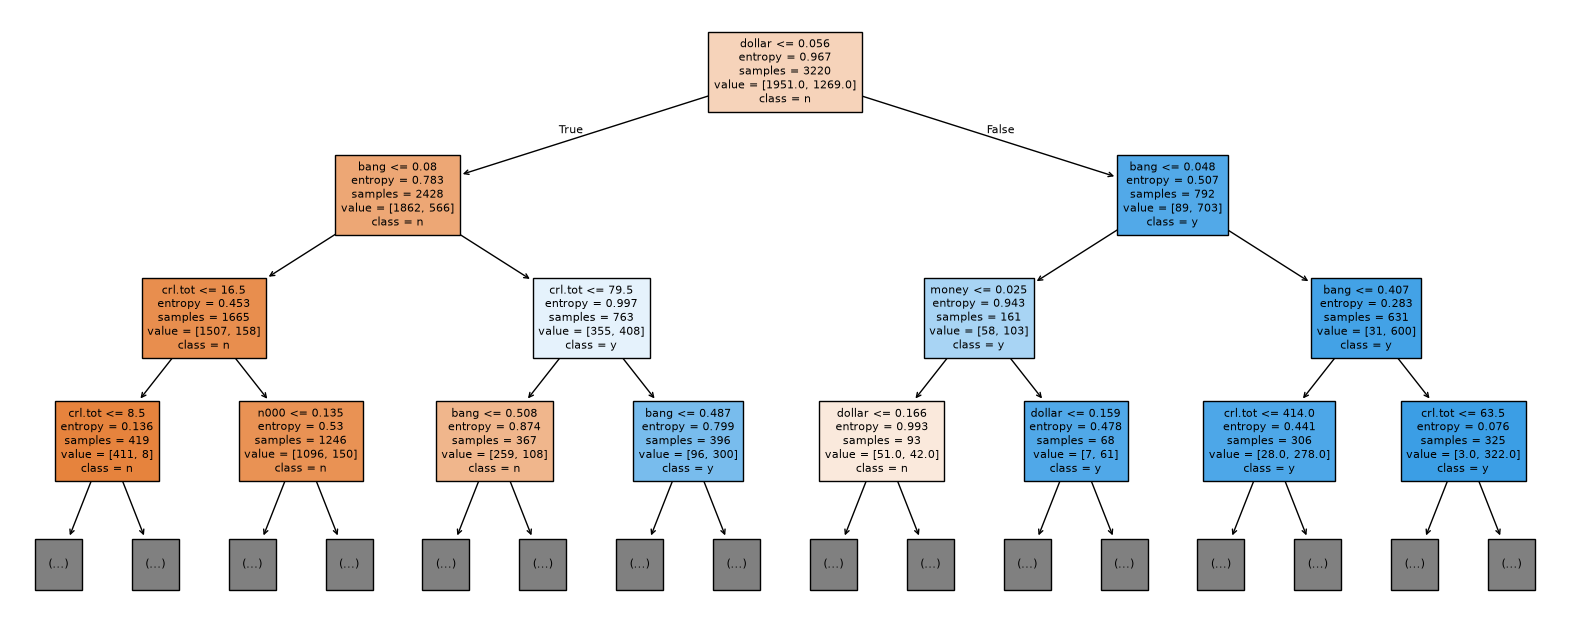

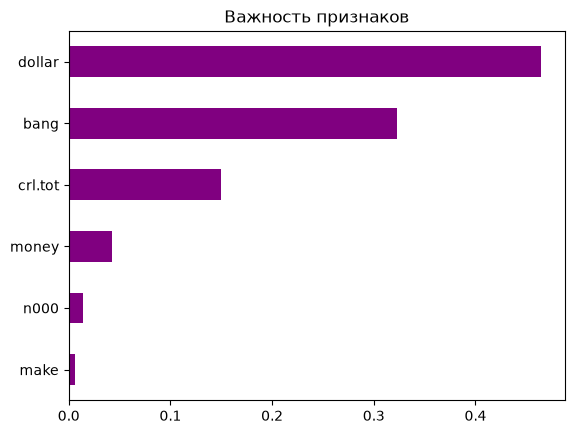

In [131]:
from sklearn.model_selection import GridSearchCV

spam7 = pd.read_csv('spam7.csv')
X5 = spam7.drop(columns='yesno')
y5 = spam7['yesno']
X5_train, X5_test, y5_train, y5_test = train_test_split(X5, y5, test_size=0.3, random_state=42, stratify=y5)

params = {'criterion': ['gini', 'entropy'],
          'max_depth': [3, 4, 5, 6, 8, 10],
          'min_samples_leaf': [1, 5, 10, 20]}
gs = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=5).fit(X5_train, y5_train)
best = gs.best_estimator_

print('Лучшие параметры:', gs.best_params_)
print('accuracy CV:', round(gs.best_score_, 3), ' test:', round(best.score(X5_test, y5_test), 3))
print(confusion_matrix(y5_test, best.predict(X5_test)))

plt.figure(figsize=(20, 8))
plot_tree(best, feature_names=list(X5.columns), class_names=list(best.classes_),
          filled=True, max_depth=3, fontsize=8)
plt.show()

pd.Series(best.feature_importances_, index=X5.columns).sort_values().plot(kind='barh', color='purple')
plt.title('Важность признаков')
plt.show()

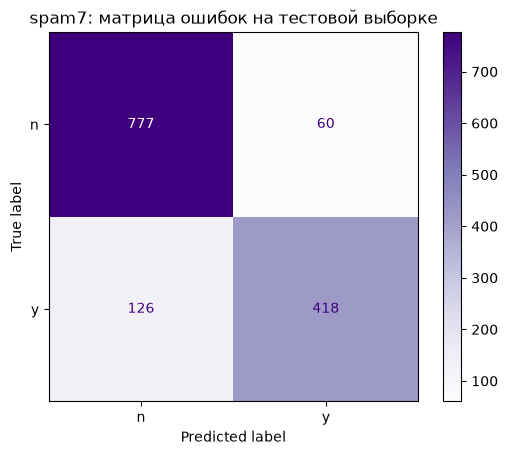

,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score
43,entropy,8,20,0.873
47,entropy,10,20,0.872
19,gini,8,20,0.872
23,gini,10,20,0.872
39,entropy,6,20,0.871
42,entropy,8,10,0.871
38,entropy,6,10,0.869
18,gini,8,10,0.869
15,gini,6,20,0.869
41,entropy,8,5,0.869


In [132]:
# spam7: матрица ошибок и лучшие комбинации параметров
ConfusionMatrixDisplay.from_estimator(best, X5_test, y5_test, cmap='Purples')
plt.title('spam7: матрица ошибок на тестовой выборке')
plt.show()

cv = pd.DataFrame(gs.cv_results_)
cv.sort_values('rank_test_score')[['param_criterion', 'param_max_depth',
                                   'param_min_samples_leaf', 'mean_test_score']].head(10).round(3)

In [133]:
# Важность признаков (таблица)
pd.Series(best.feature_importances_, index=X5.columns).sort_values(ascending=False).round(3)

dollar     0.465
bang       0.323
crl.tot    0.150
money      0.042
n000       0.014
make       0.006
dtype: float64

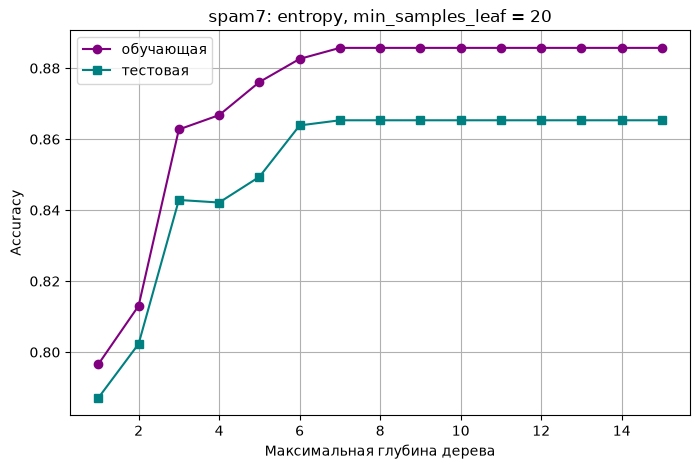

In [134]:
# spam7: accuracy от глубины при выбранных criterion и min_samples_leaf
bp = gs.best_params_
d_list = range(1, 16)
tr5, te5 = [], []
for d in d_list:
    t = DecisionTreeClassifier(criterion=bp['criterion'], min_samples_leaf=bp['min_samples_leaf'],
                               max_depth=d, random_state=42).fit(X5_train, y5_train)
    tr5.append(t.score(X5_train, y5_train))
    te5.append(t.score(X5_test, y5_test))

plt.figure(figsize=(8, 5))
plt.plot(d_list, tr5, marker='o', color='purple', label='обучающая')
plt.plot(d_list, te5, marker='s', color='teal', label='тестовая')
plt.xlabel('Максимальная глубина дерева')
plt.ylabel('Accuracy')
plt.title(f"spam7: {bp['criterion']}, min_samples_leaf = {bp['min_samples_leaf']}")
plt.legend()
plt.grid(True)
plt.show()

### Выводы по заданию 5b
дерево без ограничений на письмах избыточно (глубина 29, 442 листа, точность на тесте 0.842 при 0.975 на обучающей выборке). Оптимальное дерево подобрано перебором 48 комбинаций параметров с 5-кратной кросс-валидацией на обучающей выборке: entropy, глубина 8, минимум 20 объектов в листе. Оно меньше в 7 раз и точнее на тесте (0.865), оценки на кросс-валидации (0.873) и на тесте близки, переобучения нет. Наиболее влияющие признаки - частоты символов «$» и «!» и длина последовательностей заглавных букв.

## Задание 6. Система выдачи кредита (bank_scoring)

In [135]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, recall_score, precision_score

train6 = pd.read_csv('bank_scoring_train.csv', sep='\t')
test6 = pd.read_csv('bank_scoring_test.csv', sep='\t')
X6_train = train6.drop(columns='SeriousDlqin2yrs')
y6_train = train6['SeriousDlqin2yrs']
X6_test = test6.drop(columns='SeriousDlqin2yrs')
y6_test = test6['SeriousDlqin2yrs']
print('train:', X6_train.shape, ' test:', X6_test.shape)
print('Доля «плохих» клиентов:', round(y6_train.mean(), 3))

# SVM на 96 тысячах объектов обучается очень долго, поэтому для него берём 10 000 (с сохранением долей классов)
X6_sub, _, y6_sub, _ = train_test_split(X6_train, y6_train, train_size=10000,
                                        stratify=y6_train, random_state=42)

train: (96216, 10)  test: (24053, 10)
Доля «плохих» клиентов: 0.069


In [136]:
# Подбор дерева решений для скоринга: 5-кратная кросс-валидация на обучающей выборке, метрика ROC AUC
from sklearn.model_selection import cross_val_score
tree_rows = []
for d in [3, 4, 5, 6, 8, 10]:
    for leaf in [20, 50, 100]:
        t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, class_weight='balanced', random_state=42)
        cv_auc = cross_val_score(t, X6_train, y6_train, cv=5, scoring='roc_auc').mean()
        t.fit(X6_train, y6_train)
        tree_rows.append({'max_depth': d, 'min_samples_leaf': leaf,
                          'ROC AUC (CV)': round(cv_auc, 3),
                          'ROC AUC (test)': round(roc_auc_score(y6_test, t.predict_proba(X6_test)[:, 1]), 3),
                          'recall (test)': round(recall_score(y6_test, t.predict(X6_test)), 3)})
tree_tab = pd.DataFrame(tree_rows).sort_values('ROC AUC (CV)', ascending=False)
tree_tab.head(10)

,max_depth,min_samples_leaf,ROC AUC (CV),ROC AUC (test),recall (test)
17,10,100,0.848,0.852,0.781
16,10,50,0.846,0.851,0.770
14,8,100,0.845,0.849,0.801
13,8,50,0.844,0.847,0.801
12,8,20,0.841,0.848,0.802
10,6,50,0.840,0.842,0.750
15,10,20,0.840,0.845,0.769
11,6,100,0.840,0.842,0.751
9,6,20,0.839,0.842,0.748
8,5,100,0.836,0.836,0.784


Выбрано: max_depth = 10 , min_samples_leaf = 100


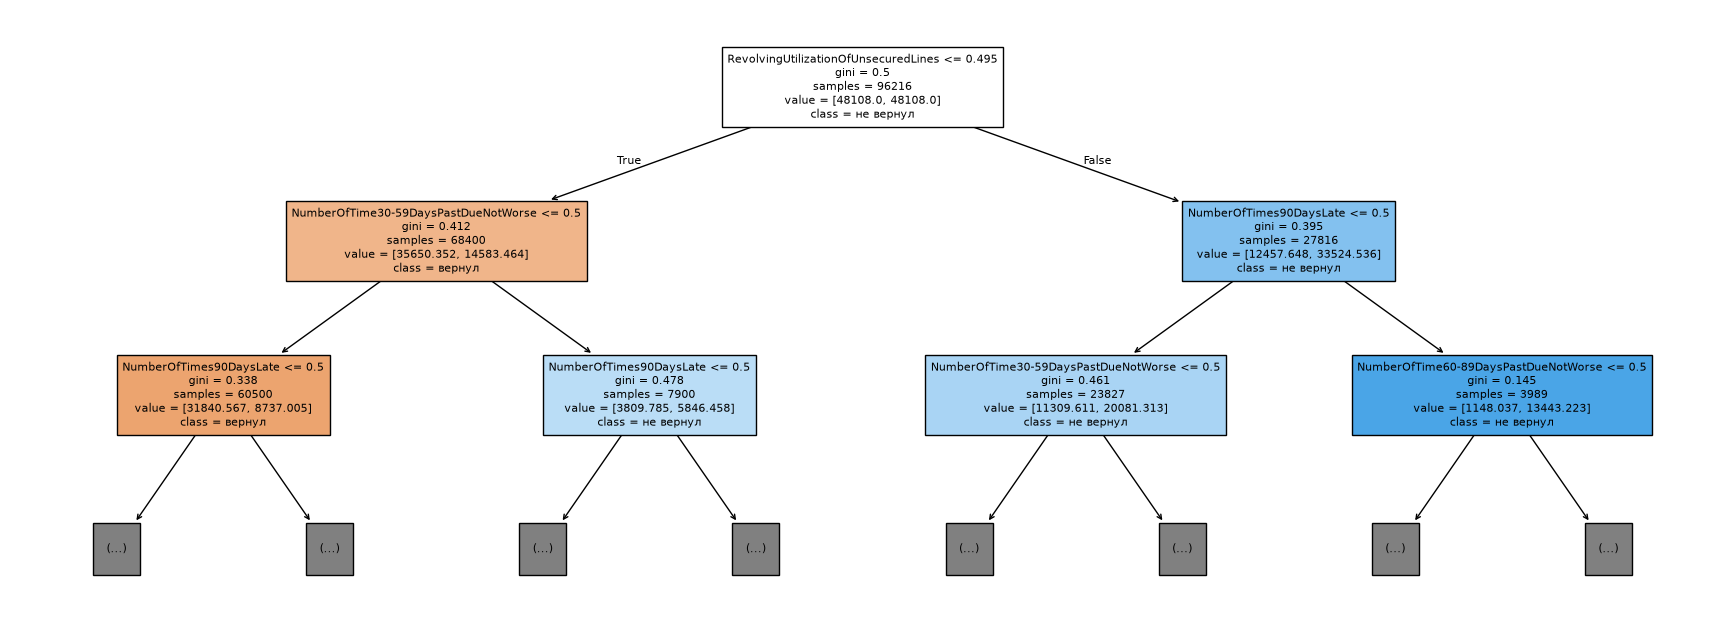

In [137]:
# Верхние уровни выбранного дерева
best_t = tree_tab.iloc[0]
tree6 = DecisionTreeClassifier(max_depth=int(best_t['max_depth']), min_samples_leaf=int(best_t['min_samples_leaf']),
                               class_weight='balanced', random_state=42).fit(X6_train, y6_train)
print('Выбрано: max_depth =', int(best_t['max_depth']), ', min_samples_leaf =', int(best_t['min_samples_leaf']))
plt.figure(figsize=(22, 8))
plot_tree(tree6, feature_names=list(X6_train.columns), class_names=['вернул', 'не вернул'],
          filled=True, max_depth=2, fontsize=8)
plt.show()

In [138]:
# Ядра SVM (обучение на 10 000 объектах, оценка на всём тестовом файле)
svm_rows = []
for kname, params in [('линейное', dict(kernel='linear')),
                      ('полином d=2', dict(kernel='poly', degree=2, coef0=1)),
                      ('полином d=3', dict(kernel='poly', degree=3, coef0=1)),
                      ('гауссово (rbf)', dict(kernel='rbf')),
                      ('сигмоида', dict(kernel='sigmoid'))]:
    m = make_pipeline(StandardScaler(), SVC(class_weight='balanced', max_iter=200000, **params)).fit(X6_sub, y6_sub)
    pred = m.predict(X6_test)
    svm_rows.append({'ядро': kname,
                     'ROC AUC': round(roc_auc_score(y6_test, m.decision_function(X6_test)), 3),
                     'recall': round(recall_score(y6_test, pred), 3),
                     'precision': round(precision_score(y6_test, pred), 3),
                     'accuracy': round(accuracy_score(y6_test, pred), 3)})
pd.DataFrame(svm_rows)

,ядро,ROC AUC,recall,precision,accuracy
0,линейное,0.806,0.564,0.266,0.864
1,полином d=2,0.809,0.605,0.261,0.856
2,полином d=3,0.800,0.624,0.235,0.835
3,гауссово (rbf),0.806,0.639,0.235,0.833
4,сигмоида,0.620,0.603,0.095,0.582


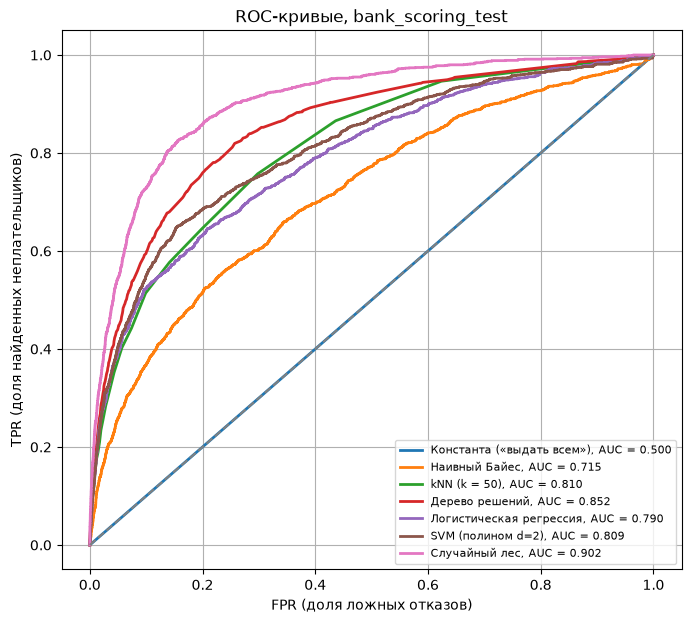

,система,ROC AUC,recall,precision,accuracy
0,Константа («выдать всем»),0.500,0.000,0.000,0.932
1,Наивный Байес,0.715,0.028,0.418,0.931
2,kNN (k = 50),0.810,0.049,0.659,0.933
3,Дерево решений,0.852,0.781,0.205,0.778
4,Логистическая регрессия,0.790,0.626,0.192,0.794
5,SVM (полином d=2),0.809,0.605,0.261,0.856
6,Случайный лес,0.902,0.808,0.292,0.853


In [139]:
# Сравнение систем на bank_scoring_test.csv
models = {'Константа («выдать всем»)': DummyClassifier(strategy='most_frequent'),
          'Наивный Байес': GaussianNB(),
          'kNN (k = 50)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=50)),
          'Дерево решений': tree6,   # выбранное дерево (max_depth и min_samples_leaf - по кросс-валидации)
          'Логистическая регрессия': make_pipeline(StandardScaler(),
                LogisticRegression(class_weight='balanced', max_iter=1000)),
          'SVM (полином d=2)': make_pipeline(StandardScaler(),
                SVC(kernel='poly', degree=2, coef0=1, class_weight='balanced', max_iter=200000)),
          'Случайный лес': RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                class_weight='balanced', random_state=42, n_jobs=-1)}

def score(m, X):   # «уверенность» модели, что клиент не вернёт кредит
    if hasattr(m, 'predict_proba'):
        return m.predict_proba(X)[:, 1]
    return m.decision_function(X)   # у SVM вместо вероятности — расстояние до границы

rows, preds = [], {}
plt.figure(figsize=(8, 7))
for name, m in models.items():
    if name.startswith('SVM'):
        m.fit(X6_sub, y6_sub)
    else:
        m.fit(X6_train, y6_train)
    s = score(m, X6_test)
    pred = m.predict(X6_test)
    preds[name] = pred
    rows.append({'система': name,
                 'ROC AUC': roc_auc_score(y6_test, s),
                 'recall': recall_score(y6_test, pred),
                 'precision': precision_score(y6_test, pred, zero_division=0),
                 'accuracy': accuracy_score(y6_test, pred)})
    fpr, tpr, _ = roc_curve(y6_test, s)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name}, AUC = {roc_auc_score(y6_test, s):.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('FPR (доля ложных отказов)')
plt.ylabel('TPR (доля найденных неплательщиков)')
plt.title('ROC-кривые, bank_scoring_test')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

pd.DataFrame(rows).round(3)

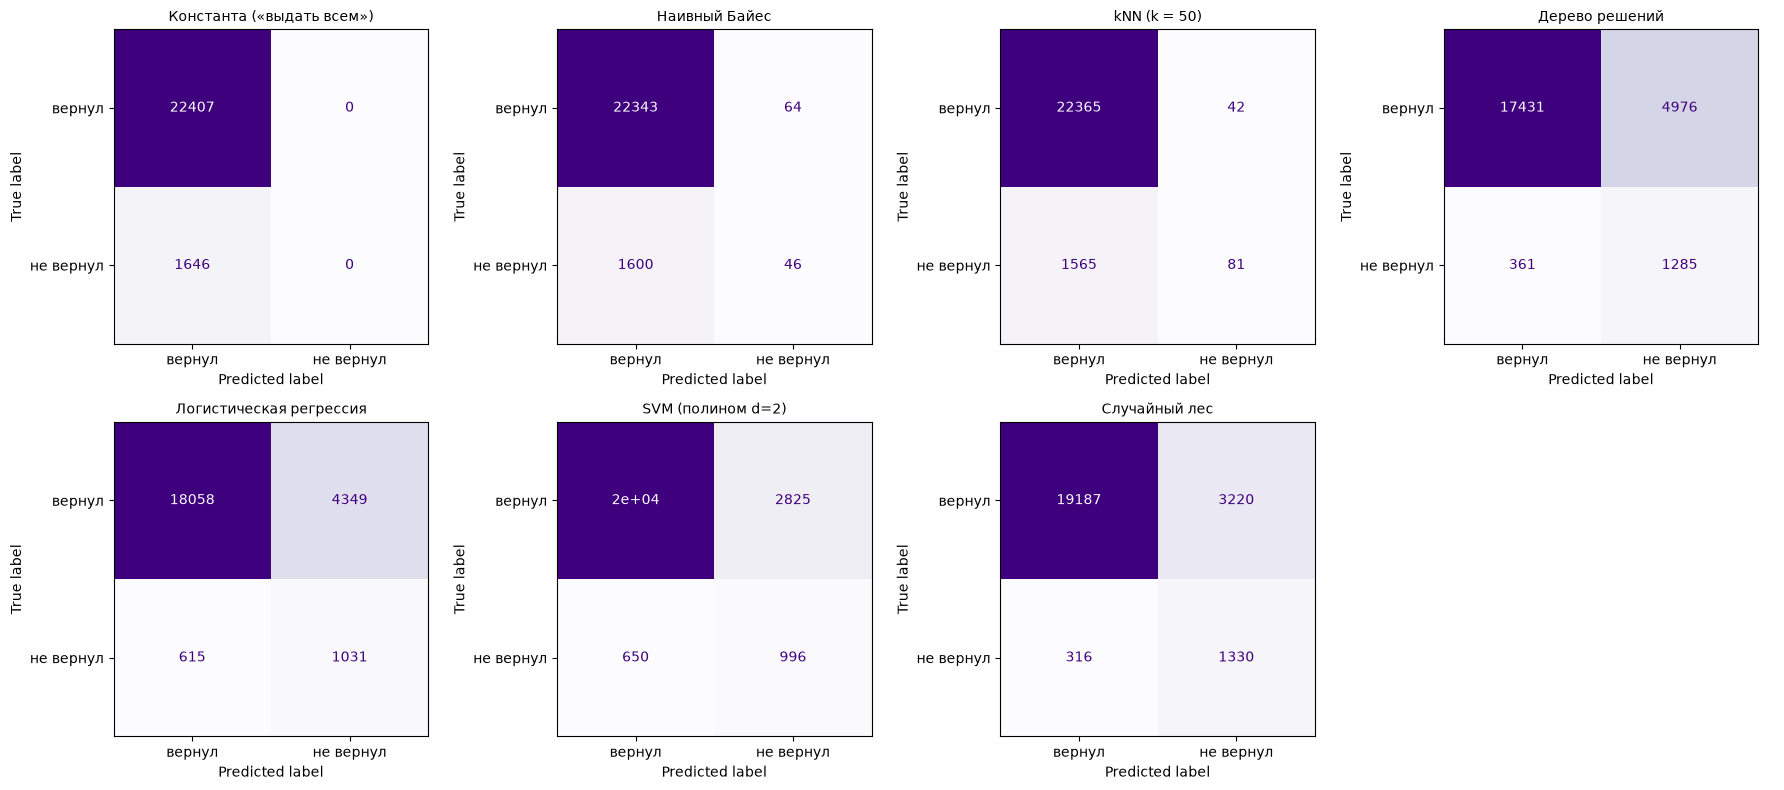

In [140]:
# Матрицы ошибок всех систем на тестовой выборке
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
ax = ax.ravel()
for i, (name, pred) in enumerate(preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y6_test, pred),
                           display_labels=['вернул', 'не вернул']).plot(cmap='Purples', ax=ax[i], colorbar=False)
    ax[i].set_title(name, fontsize=10)
ax[-1].axis('off')
plt.tight_layout()
plt.show()

### Выводы по заданию 6
Неплательщиков в данных всего около 7 %, и из-за такого дисбаланса accuracy для выбора системы не подходит: константа «выдать всем» имеет accuracy 0.932 - больше любой настоящей модели - и не находит ни одного неплательщика. Основной метрикой выбран ROC AUC, дополнительной - recall. Модели без учёта дисбаланса (наивный Байес, kNN) почти не находят неплательщиков; задание class_weight = 'balanced' решает эту проблему.

Лучшей системой оказался случайный лес: ROC AUC 0.902, recall 0.808 (находит 81 % неплательщиков), и при этом у него лучшие precision и accuracy среди систем, которые действительно находят неплательщиков. Зависимость риска от признаков нелинейная, а лес учитывает это и усредняет 200 деревьев, поэтому ошибается меньше одного дерева. На втором месте дерево решений (ROC AUC 0.852, recall 0.781), но оно чаще отказывает хорошим клиентам. Логистическая регрессия и SVM уступают обоим деревьям (ROC AUC 0.79–0.81).